# Spidey Tracker
Dataset: *Spidey Tracker: Spider-Man Dataset* (Kaggle), file `sightings.csv`.

## The problem

The Spidey Tracker takes crowd-sourced reports of Spider-Man sightings and checks
each one afterwards. About 37 per cent fail that check, and every failed report costs
reviewer time that could have gone somewhere useful. The platform already assigns each
report a `tracker_confidence` score, which is presumably meant to help reviewers decide
what to look at first.

So the question for this notebook is:

> **Which reports should a reviewer open first, and can we build a rule that beats the
> confidence score the platform already has?**

Task 1 found that `tracker_confidence` correlates with the verification outcome at
r = 0.04, which is nothing. That makes this worth asking.
## Questions

| # | Question
|---|---
| 1 | How do verification outcomes break down?
| 2 | Which reporting channels produce reliable reports?
| 3 | Does reporting delay separate verified from failed reports?
| 4 | Does submitted evidence predict verification?
| 5 | How do the numeric attributes relate to each other?
| 6 | Does corroboration behave differently across failure types?
| 7 | Does the failure mix drift over time?
| 8 | Does location help identify unreliable reports?
| 9 | Can a simple rule beat the confidence score?

## Structure

Sections 1 to 4 cover loading, the data quality audit, preprocessing and validation.
Section 5 answers the nine questions. Section 6 turns the findings into a rule.

## 0. Setup

In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
warnings.filterwarnings("ignore")

print(f"pandas {pd.__version__}, numpy {np.__version__}, seaborn {sns.__version__}")

pandas 2.2.3, numpy 2.1.3, seaborn 0.13.2


### Chart styling


Categorical colours are assigned in a fixed order, so a given verification group is the same colour in every chart. Sequential data uses one hue running light to dark, because magnitude should read as intensity. The correlation heatmap uses a diverging scale, two hues with a neutral grey midpoint, since the midpoint of a correlation is a real zero and should not look like a colour.

In [36]:
# categorical slots, assigned in order and never cycled
BLUE, ORANGE, AQUA, VIOLET = "#0072B2", "#E69F00", "#009E73", "#CC79A7"
GREY, INK, MUTED = "#b8b6ae", "#1a1a19", "#52514e"

# one colour per verification group, used consistently in every chart
GROUP_COLOURS = {
    "Verified": BLUE,
    "Deception": ORANGE,
    "Honest error": AQUA,
    "Duplicate": VIOLET,
}

GROUP_ORDER = ["Verified", "Honest error", "Deception", "Duplicate"]

# binary outcome colours
PASS_FAIL = {1: BLUE, 0: ORANGE}

# sequential, one hue light to dark
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#eaf1fb", BLUE, "#15407a"])

# diverging, two hues with a neutral grey midpoint
DIV = LinearSegmentedColormap.from_list("div_ob", [ORANGE, "#e8e6e1", BLUE])

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.labelcolor": MUTED,
    "axes.edgecolor": GREY,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e8e6e1",
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})


# strip the chart down to the marks, keeping only the gridlines that help
def style_axes(ax, grid_axis="y"):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, alpha=0.7)
    ax.grid(axis="x" if grid_axis == "y" else "y", visible=False)
    ax.set_axisbelow(True)
    return ax


# write values directly on the bars, so the reader is not tracing back to an axis
def label_bars(ax, fmt="{:.1f}", horizontal=False, pad=3, colour=INK, skip_zero=False):
    for patch in ax.patches:
        if horizontal:
            value = patch.get_width()
            x, y = value, patch.get_y() + patch.get_height() / 2
            ha, va = "left", "center"
            offset = (pad, 0)
        else:
            value = patch.get_height()
            x, y = patch.get_x() + patch.get_width() / 2, value
            ha, va = "center", "bottom"
            offset = (0, pad)

        if pd.isna(value) or (skip_zero and value == 0):
            continue
        ax.annotate(fmt.format(value), (x, y), textcoords="offset points",
                    xytext=offset, ha=ha, va=va, fontsize=8.5, color=colour)


# a short note under the chart saying what the reader should take from it
def caption(fig, text):
    fig.text(0.0, -0.02, text, ha="left", va="top", fontsize=9, color=MUTED, wrap=True)

### Config

Every column list, threshold and mapping lives here, so nothing further down hard-codes
a column name.

In [37]:
DATA_DIRS = [
    "/Users/khushi/Documents/proet/spidey/v1",
    "/content/drive/MyDrive/Colab Notebooks/43031/v1",
    "./v1",
    ".",
]

FILENAME = "sightings.csv"

# numeric columns filled on every row
NUM_COLS = [
    "witness_count",
    "tracker_confidence",
    "visibility_m",
    "crowd_density_score",
    "location_spread_m",
    "median_report_delay_s",
]

# booleans describing what came with the report, cast to int during preprocessing
FLAG_COLS = [
    "photo_evidence",
    "video_evidence",
    "audio_evidence",
    "web_residue_found",
    "police_report_linked",
    "crime_nearby",
]

# the three a reporter submits themselves
SUBMITTED = ["photo_evidence", "video_evidence", "audio_evidence"]

# the three that come from somewhere other than the reporter
CORROBORATING = ["web_residue_found", "police_report_linked", "crime_nearby"]

OUTCOME_COL = "is_verified"

CAT_COLS = [
    "borough",
    "district",
    "report_type",
    "movement_direction",
    "weather_condition",
    "report_source",
    "verification_status",
]

# columns blank by design, with the column that decides when
MISSING_RULES = {
    "mean_photo_quality": {"depends_on": "photo_evidence", "blank_when": [False]},
    "distance_to_nearest_crime_m": {"depends_on": "crime_nearby", "blank_when": [False]},
    "minutes_from_nearest_crime": {"depends_on": "crime_nearby", "blank_when": [False]},
    "estimated_speed_kmh": {"depends_on": "report_type", "blank_when": ["stationary"]},
    "estimated_altitude_m": {"depends_on": "report_type", "blank_when": ["stationary", "street"]},
}

# seven outcomes collapsed by the kind of failure
VERIFICATION_GROUPS = {
    "verified": "Verified",
    "mistaken_identity": "Honest error",
    "sensor_error": "Honest error",
    "impersonator": "Deception",
    "social_media_hoax": "Deception",
    "deliberate_fake": "Deception",
    "duplicate_report": "Duplicate",
}

GROUP_COL = "verification_group"

# a web swing tops out somewhere near this, anything past it is not physical
MAX_PLAUSIBLE_SPEED_KMH = 320

IQR_MULTIPLIER = 1.5

print(f"{len(NUM_COLS)} numeric, {len(FLAG_COLS)} flags, {len(CAT_COLS)} categorical")

6 numeric, 6 flags, 7 categorical


## 1. Load and inspect

In [38]:
# banner so printed output is easy to scan
def header(text):
    line = "=" * 80
    print(f"\n{line}\n{text.upper()}\n{line}")


# fail early if a configured column name is wrong
def check_cols(df, cols):
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise Exception(f"not in the dataframe: {', '.join(missing)}")


# first directory that actually holds the file
def find_data_dir(candidates, filename):
    for c in candidates:
        if (Path(c) / filename).is_file():
            print(f"data dir: {c}")
            return Path(c)
    raise Exception(f"cant find {filename}, checked: {', '.join(candidates)}")


# read the csv, with a readable message if anything goes wrong
def load_csv(directory, filename):
    path = Path(directory) / filename
    try:
        df = pd.read_csv(path)
    except Exception as e:
        raise Exception(f"couldnt read {path}: {e}")

    if df.empty:
        raise Exception(f"{path} parsed but came back empty")

    print(f"loaded {filename}: {df.shape[0]:,} rows x {df.shape[1]} cols")
    return df


# one row per column: type, completeness, cardinality, example
def inspect(df):
    rows = []
    for c in df.columns:
        s = df[c]
        vals = s.dropna()
        example = "-" if vals.empty else str(vals.iloc[0])[:24]
        rows.append({
            "column": c,
            "dtype": str(s.dtype),
            "missing": int(s.isna().sum()),
            "missing %": round(s.isna().mean() * 100, 2),
            "unique": int(s.nunique(dropna=True)),
            "example": example,
        })
    return pd.DataFrame(rows)

In [39]:
header("1. load and inspect")

data_dir = find_data_dir(DATA_DIRS, FILENAME)
raw = load_csv(data_dir, FILENAME)

display(raw.head())
display(inspect(raw))


1. LOAD AND INSPECT
data dir: /content/drive/MyDrive/Colab Notebooks/43031/v1
loaded sightings.csv: 86,631 rows x 33 cols


,sighting_id,split,timestamp,latitude,longitude,borough,district,h3_cell,report_type,witness_count,unique_source_count,tracker_confidence,photo_evidence,mean_photo_quality,video_evidence,audio_evidence,web_residue_found,police_report_linked,crime_nearby,nearest_crime_id,distance_to_nearest_crime_m,minutes_from_nearest_crime,estimated_speed_kmh,estimated_altitude_m,movement_direction,weather_condition,visibility_m,crowd_density_score,report_source,location_spread_m,median_report_delay_s,verification_status,is_verified
0,SPY_00000000,train,2025-01-01 00:03:26.000000000,40.599,-74.011,Brooklyn,Brooklyn_Central_0,882a10742dfffff,street,3,3,0.562,False,NaN,False,True,False,False,False,NaN,NaN,NaN,56.333,NaN,N,cloudy,"11,875.000",0.685,mobile_app,28.400,249.000,verified,1
1,SPY_00000001,train,2025-01-01 00:12:30.000000000,40.694,-73.932,Brooklyn,Brooklyn_North_10,882a100d89fffff,street,3,3,0.416,False,NaN,True,False,False,False,False,NaN,NaN,NaN,65.600,NaN,NW,cloudy,"11,875.000",0.413,mobile_app,112.100,720.000,mistaken_identity,0
2,SPY_00000002,test,2025-01-01 00:16:57.000000000,40.670,-73.927,Queens,Queens_Southeast_4,882a100d91fffff,swinging,1,1,0.480,True,0.588,False,False,False,False,False,NaN,NaN,NaN,15.100,102.600,E,cloudy,"11,875.000",0.519,camera_network,0.000,275.000,verified,1
3,SPY_00000003,test,2025-01-01 00:24:51.000000000,40.741,-73.994,Manhattan,Manhattan_North_1,882a100d21fffff,swinging,1,1,0.371,True,0.179,False,False,False,False,False,NaN,NaN,NaN,92.200,14.900,NW,cloudy,"11,875.000",0.590,social_media,0.000,400.000,verified,1
4,SPY_00000004,train,2025-01-01 00:35:04.425366238,40.826,-73.946,Manhattan,Manhattan_West_7,882a100aa3fffff,stationary,2,2,0.485,True,0.267,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,W,cloudy,"11,875.000",0.581,social_media,38.300,318.500,verified,1


,column,dtype,missing,missing %,unique,example
0,sighting_id,object,0,0.000,86631,SPY_00000000
1,split,object,0,0.000,2,train
2,timestamp,object,0,0.000,86561,2025-01-01 00:03:26.0000
3,latitude,float64,0,0.000,32549,40.59937
4,longitude,float64,0,0.000,30704,-74.01136
5,borough,object,0,0.000,5,Brooklyn
6,district,object,0,0.000,46,Brooklyn_Central_0
7,h3_cell,object,0,0.000,1513,882a10742dfffff
8,report_type,object,0,0.000,7,street
9,witness_count,int64,0,0.000,46,3


## 2. Data quality audit

Five checks run before anything is changed. Each returns a table rather than printing,
so the same functions can be re-run in Section 4 to confirm the fixes worked.

The audit comes first and the fixes come second on purpose. Several of these issues
look like one thing and turn out to be another, and the obvious fix would have been
wrong in at least two cases.

### 2.1 Missing values

In [40]:
# is each sparse column blank exactly where its governing column says it should be?
def audit_missing(df, rules):
    rows = []
    for col, rule in rules.items():
        on, blank_when = rule["depends_on"], rule["blank_when"]
        check_cols(df, [col, on])

        expected = df[on].isin(blank_when)
        actual = df[col].isna()
        breaks = int((expected != actual).sum())

        rows.append({
            "column": col,
            "missing %": round(actual.mean() * 100, 2),
            "governed by": on,
            "expected blank": int(expected.sum()),
            "actually blank": int(actual.sum()),
            "breaks": breaks,
            "structural": breaks == 0,
        })
    return pd.DataFrame(rows)


# any column with blanks the rules above do not account for
def unexplained_missing(df, rules):
    known = set(rules)
    counts = df.isna().sum()
    return counts[(counts > 0) & (~counts.index.isin(known))]

In [41]:
header("2. data quality audit")

print("2.1 missing values")
missing_audit = audit_missing(raw, MISSING_RULES)
display(missing_audit)

leftover = unexplained_missing(raw, MISSING_RULES)
print(f"columns with blanks not covered by a rule: {len(leftover)}")
if len(leftover):
    display(leftover)

if missing_audit["structural"].all():
    print("\nevery rule holds exactly, so these blanks mean the column does not apply")
    print("to that kind of sighting rather than a value having been lost")


2. DATA QUALITY AUDIT
2.1 missing values


,column,missing %,governed by,expected blank,actually blank,breaks,structural
0,mean_photo_quality,31.990,photo_evidence,27709,27709,0,True
1,distance_to_nearest_crime_m,92.990,crime_nearby,80559,80559,0,True
2,minutes_from_nearest_crime,92.990,crime_nearby,80559,80559,0,True
3,estimated_speed_kmh,17.490,report_type,15152,15152,0,True
4,estimated_altitude_m,46.260,report_type,40074,40074,0,True


columns with blanks not covered by a rule: 1


,0
nearest_crime_id,80559



every rule holds exactly, so these blanks mean the column does not apply
to that kind of sighting rather than a value having been lost


The one column the rules do not cover is `nearest_crime_id`, which is blank under the
same `crime_nearby` condition as the two crime measurements. It is an identifier rather
than a measurement, so it is reported here for completeness and then set aside.

**What this means for the fix.** None of these are lost values. `estimated_altitude_m`
is blank for street-level sightings because a street-level sighting has no height above
the ground, not because someone forgot to record one. Mean imputation would invent
40,074 observations that cannot exist.

The fix is to keep the blanks and add an explicit indicator column for each, so the
fact that a measurement was unavailable becomes usable information instead of a hole.

### 2.2 Duplicates

In [42]:
# exact row copies, repeated ids, and duplicates the dataset flags itself
def audit_duplicates(df, id_col, status_col, dup_label):
    check_cols(df, [id_col, status_col])

    # a duplicate report is the same event filed twice, so compare on what was observed
    # rather than on the whole row, which carries a unique id
    content = ["timestamp", "latitude", "longitude", "report_type", "report_source"]
    content = [c for c in content if c in df.columns]

    return pd.DataFrame([
        {"check": "exact row copies", "count": int(df.duplicated().sum())},
        {"check": "repeated ids", "count": int(df[id_col].duplicated().sum())},
        {"check": "same event, same source", "count": int(df.duplicated(subset=content).sum())},
        {"check": "flagged duplicate_report", "count": int((df[status_col] == dup_label).sum())},
    ])

In [43]:
print("2.2 duplicates")
dup_audit = audit_duplicates(raw, "sighting_id", "verification_status", "duplicate_report")
display(dup_audit)

2.2 duplicates


,check,count
0,exact row copies,0
1,repeated ids,0
2,"same event, same source",0
3,flagged duplicate_report,4802


**What this means for the fix.** There are no exact row copies and no repeated ids, so
the standard `drop_duplicates()` call would remove nothing and report a clean dataset.

The dataset nonetheless labels thousands of reports as duplicates through
`verification_status`. These are real sightings filed more than once, and they are not
errors to delete. Dropping them would throw away a whole category of reviewer workload,
which is exactly what this analysis is about. They are kept and treated as their own
group.

### 2.3 Outliers

Two different things get called an outlier here, and they need different treatment.

A statistical outlier is a value far from the rest of its distribution. Most of these
columns are heavily right-skewed, so the interquartile range is used rather than a
standard deviation rule, which would be dragged around by the same extreme values it is
supposed to catch.

An impossible value is one that breaks a rule about the world. Those are the ones worth
acting on.

In [44]:
# values outside the interquartile fences
def iqr_bounds(s, multiplier=IQR_MULTIPLIER):
    vals = s.dropna()
    if vals.empty:
        return np.nan, np.nan

    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    iqr = q3 - q1

    # quartiles collapse onto each other when most values are identical, and the fences
    # are meaningless when that happens
    if iqr == 0:
        return np.nan, np.nan

    return q1 - multiplier * iqr, q3 + multiplier * iqr


# skew, outlier count and range for each numeric column
def audit_outliers(df, cols):
    check_cols(df, cols)
    rows = []

    for c in cols:
        vals = df[c].dropna()
        low, high = iqr_bounds(df[c])

        if pd.isna(low):
            n_out, pct = 0, 0.0
            note = "quartiles identical, IQR undefined"
        else:
            n_out = int(((vals < low) | (vals > high)).sum())
            pct = round(n_out / len(vals) * 100, 2) if len(vals) else 0.0
            note = ""

        rows.append({
            "column": c,
            "skew": round(vals.skew(), 2) if len(vals) > 2 else np.nan,
            "min": vals.min(),
            "median": vals.median(),
            "max": vals.max(),
            "iqr outliers": n_out,
            "outlier %": pct,
            "note": note,
        })

    return pd.DataFrame(rows).set_index("column")


# values that break a rule about the world rather than a rule about the distribution
def audit_impossible(df):
    checks = []

    if "estimated_speed_kmh" in df:
        over = df["estimated_speed_kmh"] > MAX_PLAUSIBLE_SPEED_KMH
        checks.append({
            "check": f"speed above {MAX_PLAUSIBLE_SPEED_KMH} km/h",
            "count": int(over.sum()),
            "detail": f"max observed {df['estimated_speed_kmh'].max():,.1f}",
        })

    if "minutes_from_nearest_crime" in df:
        neg = df["minutes_from_nearest_crime"] < 0
        checks.append({
            "check": "negative minutes from crime",
            "count": int(neg.sum()),
            "detail": f"range {df['minutes_from_nearest_crime'].min():,.1f} to "
                      f"{df['minutes_from_nearest_crime'].max():,.1f}",
        })

    if "distance_to_nearest_crime_m" in df:
        applicable = df["distance_to_nearest_crime_m"].dropna()
        zeros = int((applicable == 0).sum())
        checks.append({
            "check": "distance to crime exactly zero",
            "count": zeros,
            "detail": f"{zeros / len(applicable) * 100:.1f}% of applicable rows" if len(applicable) else "-",
        })

    if {"witness_count", "unique_source_count"} <= set(df.columns):
        diff = df["witness_count"] - df["unique_source_count"]
        off = diff.ne(0) & diff.notna()
        detail = "-" if not off.any() else f"all differ by exactly {diff[off].abs().unique()}"
        checks.append({
            "check": "witness_count != unique_source_count",
            "count": int(off.sum()),
            "detail": detail,
        })

    return pd.DataFrame(checks)

In [45]:
print("2.3 outliers")
display(audit_outliers(raw, NUM_COLS + list(MISSING_RULES)))

print("\nvalues that break a rule about the world")
display(audit_impossible(raw))

2.3 outliers


,skew,min,median,max,iqr outliers,outlier %,note
column,,,,,,,
witness_count,2.510,1.000,3.000,49.000,4808,5.550,
tracker_confidence,0.110,0.208,0.518,0.869,92,0.110,
visibility_m,-1.050,154.000,"8,615.000","11,998.000",4966,5.730,
crowd_density_score,-0.230,0.113,0.499,0.782,0,0.000,
location_spread_m,2.020,0.000,52.000,"1,044.900",3789,4.370,
median_report_delay_s,3.670,24.000,327.000,"4,231.000",5007,5.780,
mean_photo_quality,-0.060,0.020,0.508,0.990,0,0.000,
distance_to_nearest_crime_m,10.280,0.000,0.000,"1,752.600",0,0.000,"quartiles identical, IQR undefined"
minutes_from_nearest_crime,-1.890,-89.470,5.600,89.630,387,6.370,



values that break a rule about the world


,check,count,detail
0,speed above 320 km/h,122,max observed 908.4
1,negative minutes from crime,115,range -89.5 to 89.6
2,distance to crime exactly zero,5261,86.6% of applicable rows
3,witness_count != unique_source_count,145,all differ by exactly [1]


**What this means for the fix.** The IQR outliers in `median_report_delay_s` and
`location_spread_m` are the long tail of a skewed distribution, not errors. Removing
them would delete the slow reports, and Task 1 found reporting delay is the single
strongest predictor of the verification outcome, so those rows carry the signal. They
stay.

Three findings do need handling. Speeds far above anything a person can travel are
physically impossible and get flagged rather than deleted, since an impossible speed is
itself a sign of a bad report. `distance_to_nearest_crime_m` is overwhelmingly exact
zeros, so it behaves as a yes-or-no flag rather than a measurement and will be used that
way. `minutes_from_nearest_crime` runs negative, which means the sighting came before
the crime rather than after, so the sign carries meaning and the magnitude needs its own
column.

### 2.4 Data types

In [46]:
# columns stored as something that will not support the operations needed
def audit_dtypes(df, flags, cats):
    rows = []

    if "timestamp" in df:
        rows.append({
            "column": "timestamp",
            "stored as": str(df["timestamp"].dtype),
            "should be": "datetime64",
            "why": "cannot resample or extract an hour from text",
        })

    for c in flags:
        if c in df and not pd.api.types.is_integer_dtype(df[c]):
            rows.append({
                "column": c,
                "stored as": str(df[c].dtype),
                "should be": "int8",
                "why": "booleans cannot enter a correlation matrix",
            })

    for c in cats:
        if c in df and df[c].nunique() < 50:
            rows.append({
                "column": c,
                "stored as": str(df[c].dtype),
                "should be": "category",
                "why": f"only {df[c].nunique()} distinct values, stored as text",
            })

    return pd.DataFrame(rows)

In [47]:
print("2.4 data types")
display(audit_dtypes(raw, FLAG_COLS, CAT_COLS))

2.4 data types


,column,stored as,should be,why
0,timestamp,object,datetime64,cannot resample or extract an hour from text
1,photo_evidence,bool,int8,booleans cannot enter a correlation matrix
2,video_evidence,bool,int8,booleans cannot enter a correlation matrix
3,audio_evidence,bool,int8,booleans cannot enter a correlation matrix
4,web_residue_found,bool,int8,booleans cannot enter a correlation matrix
5,police_report_linked,bool,int8,booleans cannot enter a correlation matrix
6,crime_nearby,bool,int8,booleans cannot enter a correlation matrix
7,borough,object,category,"only 5 distinct values, stored as text"
8,district,object,category,"only 46 distinct values, stored as text"
9,report_type,object,category,"only 7 distinct values, stored as text"


### 2.5 Categorical consistency

In [48]:
# stray casing, padding or near-duplicate labels in the categorical columns
def audit_categories(df, cols):
    check_cols(df, cols)
    rows = []

    for c in cols:
        vals = df[c].dropna().astype(str)
        rows.append({
            "column": c,
            "levels": int(vals.nunique()),
            "padded": int((vals != vals.str.strip()).sum()),
            "mixed case": int(vals.nunique() - vals.str.lower().nunique()),
            "empty strings": int((vals.str.strip() == "").sum()),
        })

    return pd.DataFrame(rows).set_index("column")

In [49]:
print("2.5 categorical consistency")
display(audit_categories(raw, CAT_COLS))

2.5 categorical consistency


,levels,padded,mixed case,empty strings
column,,,,
borough,5,0,0,0
district,46,0,0,0
report_type,7,0,0,0
movement_direction,8,0,0,0
weather_condition,6,0,0,0
report_source,6,0,0,0
verification_status,7,0,0,0


## 3. Preprocessing

Eight steps, each following from something the audit found. The guiding rule is that no
row is deleted unless it is genuinely unusable, because this analysis is about reviewer
workload and deleting the awkward reports would delete the problem.

| # | Step | Why |
|---|---|---|
| 1 | Parse `timestamp` to datetime | stored as text, needed for resampling |
| 2 | Cast evidence flags to int8 | booleans cannot enter a correlation matrix |
| 3 | Convert low-cardinality text to category | smaller and gives a fixed level order |
| 4 | Add a `_recorded` indicator per sparse column | keeps the blank, makes its absence usable |
| 5 | Flag impossible speeds instead of deleting | an impossible speed is itself a signal |
| 6 | Split the crime columns into usable parts | one is really a flag, the other is signed |
| 7 | Drop `unique_source_count` | duplicates `witness_count` |
| 8 | Derive grouping, time and evidence-count columns | needed by the questions below |

Each step is a function that returns a new frame, so the raw version stays available
for comparison.

In [50]:
# text to datetime, warning if any value refuses to parse
def fix_timestamp(df, col="timestamp"):
    out = df.copy()
    out[col] = pd.to_datetime(out[col], errors="coerce")

    failed = int(out[col].isna().sum())
    print(f"  1. {col} parsed to datetime, {failed:,} failures")
    return out


# booleans to 0 and 1 so they work in correlations and means
def fix_flags(df, flags):
    check_cols(df, flags)
    out = df.copy()

    for c in flags:
        out[c] = out[c].astype("Int8") if out[c].isna().any() else out[c].astype("int8")

    print(f"  2. {len(flags)} evidence flags cast to integer")
    return out


# repeated text to category, which also fixes the level order in charts
def fix_categories(df, cols, max_levels=50):
    out = df.copy()
    converted = 0

    for c in cols:
        if c in out and out[c].nunique() <= max_levels:
            out[c] = out[c].astype("category")
            converted += 1

    print(f"  3. {converted} text columns converted to category")
    return out


# keep the blank, add a column saying whether the measurement exists
def add_recorded_flags(df, rules):
    out = df.copy()

    for col in rules:
        out[f"{col}_recorded"] = out[col].notna().astype("int8")

    print(f"  4. added {len(rules)} _recorded indicator columns")
    return out


# mark speeds no person could reach, rather than dropping those rows
def flag_impossible_speed(df, limit=MAX_PLAUSIBLE_SPEED_KMH, col="estimated_speed_kmh"):
    out = df.copy()
    out["speed_impossible"] = (out[col] > limit).fillna(False).astype("int8")

    n = int(out["speed_impossible"].sum())
    print(f"  5. flagged {n:,} sightings above {limit} km/h, none deleted")
    return out


# distance is really a yes or no, and the time gap has a direction worth keeping
def split_crime_columns(df):
    out = df.copy()

    # 87% of applicable values are exactly zero, so this is at-the-scene or not
    out["crime_at_scene"] = (out["distance_to_nearest_crime_m"] == 0).fillna(False).astype("int8")

    # negative means the sighting came first, so sign and size are separate facts
    out["sighting_before_crime"] = (out["minutes_from_nearest_crime"] < 0).fillna(False).astype("int8")
    out["minutes_from_crime_abs"] = out["minutes_from_nearest_crime"].abs()

    print("  6. derived crime_at_scene, sighting_before_crime, minutes_from_crime_abs")
    return out


# remove the column that repeats another one
def drop_redundant(df, col="unique_source_count", twin="witness_count"):
    out = df.copy()

    if col not in out:
        return out

    agreement = (out[col] == out[twin]).mean()
    out = out.drop(columns=[col])
    print(f"  7. dropped {col}, which matched {twin} on {agreement:.2%} of rows")
    return out


# the grouping, time and evidence-count columns the questions need
def add_derived(df, groups, submitted, corroborating):
    out = df.copy()

    out[GROUP_COL] = out["verification_status"].map(groups)
    unmapped = int(out[GROUP_COL].isna().sum())
    if unmapped:
        print(f"     warning: {unmapped:,} rows have a status outside the mapping")
        out[GROUP_COL] = out[GROUP_COL].fillna("Unmapped")
    out[GROUP_COL] = pd.Categorical(out[GROUP_COL], categories=GROUP_ORDER, ordered=False)

    out["report_hour"] = out["timestamp"].dt.hour
    out["report_month"] = out["timestamp"].dt.to_period("M").dt.to_timestamp()
    out["report_weekday"] = out["timestamp"].dt.day_name()

    # how many of each kind of evidence a report carries
    out["submitted_count"] = out[submitted].sum(axis=1).astype("int8")
    out["corroboration_count"] = out[corroborating].sum(axis=1).astype("int8")

    print("  8. derived verification_group, time parts and evidence counts")
    return out


# run the whole pipeline in order
def preprocess(df):
    out = fix_timestamp(df)
    out = fix_flags(out, FLAG_COLS)
    out = fix_categories(out, CAT_COLS)
    out = add_recorded_flags(out, MISSING_RULES)
    out = flag_impossible_speed(out)
    out = split_crime_columns(out)
    out = drop_redundant(out)
    out = add_derived(out, VERIFICATION_GROUPS, SUBMITTED, CORROBORATING)
    return out

In [51]:
header("3. preprocessing")

df = preprocess(raw)

print(f"\n{raw.shape[1]} columns in, {df.shape[1]} columns out, "
      f"{len(df):,} rows unchanged")


3. PREPROCESSING
  1. timestamp parsed to datetime, 0 failures
  2. 6 evidence flags cast to integer
  3. 7 text columns converted to category
  4. added 5 _recorded indicator columns
  5. flagged 122 sightings above 320 km/h, none deleted
  6. derived crime_at_scene, sighting_before_crime, minutes_from_crime_abs
  7. dropped unique_source_count, which matched witness_count on 99.83% of rows
  8. derived verification_group, time parts and evidence counts

33 columns in, 47 columns out, 86,631 rows unchanged


## 4. Validation


In [52]:
# confirm the pipeline did what it claimed and broke nothing on the way
def validate(before, after):
    results = []

    def check(name, passed, detail=""):
        results.append({"check": name, "passed": bool(passed), "detail": detail})

    check("no rows lost", len(before) == len(after), f"{len(before):,} in, {len(after):,} out")

    check("timestamp is datetime",
          pd.api.types.is_datetime64_any_dtype(after["timestamp"]),
          str(after["timestamp"].dtype))

    bad_flags = [c for c in FLAG_COLS if not pd.api.types.is_integer_dtype(after[c])]
    check("flags are integer", not bad_flags, "all int8" if not bad_flags else str(bad_flags))

    flag_range_ok = all(set(after[c].dropna().unique()) <= {0, 1} for c in FLAG_COLS)
    check("flags only hold 0 or 1", flag_range_ok)

    derived = [GROUP_COL, "report_hour", "submitted_count", "corroboration_count",
               "crime_at_scene", "speed_impossible"]
    gaps = {c: int(after[c].isna().sum()) for c in derived if after[c].isna().any()}
    check("derived columns complete", not gaps, "no gaps" if not gaps else str(gaps))

    check("group covers every row",
          after[GROUP_COL].notna().all(),
          f"{after[GROUP_COL].nunique()} groups")

    # the sparse columns should still be exactly as blank as before
    preserved = all(
        before[c].isna().sum() == after[c].isna().sum() for c in MISSING_RULES
    )
    check("structural blanks preserved", preserved, "nothing silently imputed")

    return pd.DataFrame(results)

In [53]:
header("4. validation")

report = validate(raw, df)
display(report)

if report["passed"].all():
    print("all checks passed")
else:
    raise Exception(f"validation failed: {report.loc[~report['passed'], 'check'].tolist()}")


4. VALIDATION


,check,passed,detail
0,no rows lost,True,"86,631 in, 86,631 out"
1,timestamp is datetime,True,datetime64[ns]
2,flags are integer,True,all int8
3,flags only hold 0 or 1,True,
4,derived columns complete,True,no gaps
5,group covers every row,True,4 groups
6,structural blanks preserved,True,nothing silently imputed


all checks passed


In [54]:
# re-run the audits on the cleaned frame to show what changed
print("missing value audit, after preprocessing")
display(audit_missing(df, MISSING_RULES))

print("dtype audit, after preprocessing")
after_dtypes = audit_dtypes(df, FLAG_COLS, CAT_COLS)
display(after_dtypes if len(after_dtypes) else "no dtype issues remaining")

missing value audit, after preprocessing


,column,missing %,governed by,expected blank,actually blank,breaks,structural
0,mean_photo_quality,31.990,photo_evidence,27709,27709,0,True
1,distance_to_nearest_crime_m,92.990,crime_nearby,80559,80559,0,True
2,minutes_from_nearest_crime,92.990,crime_nearby,80559,80559,0,True
3,estimated_speed_kmh,17.490,report_type,15152,15152,0,True
4,estimated_altitude_m,46.260,report_type,40074,40074,0,True


dtype audit, after preprocessing


,column,stored as,should be,why
0,timestamp,datetime64[ns],datetime64,cannot resample or extract an hour from text
1,borough,category,category,"only 5 distinct values, stored as text"
2,district,category,category,"only 46 distinct values, stored as text"
3,report_type,category,category,"only 7 distinct values, stored as text"
4,movement_direction,category,category,"only 8 distinct values, stored as text"
5,weather_condition,category,category,"only 6 distinct values, stored as text"
6,report_source,category,category,"only 6 distinct values, stored as text"
7,verification_status,category,category,"only 7 distinct values, stored as text"


The missing value audit still reports the same blanks, which is the intended outcome.
Those columns describe measurements that do not exist for that kind of sighting, so
the correct result is that they stay blank and the new `_recorded` columns carry the
information instead.

## 5. Analytical questions

Nine questions. Each one states what is being asked, says why that chart type suits the
data, and reads the result underneath.

### Q1. How do verification outcomes break down?

A share-of-whole question with four mutually exclusive parts that sum to the dataset.
A donut suits that and nothing else here does, so this is the only part-to-whole chart
in the notebook. Everything after this compares groups rather than dividing a total,
which is a job for bars.


Q1. VERIFICATION OUTCOME MIX


,reports,share %
verification_group,,
Verified,"54,611.000",63.040
Honest error,"11,370.000",13.120
Deception,"15,848.000",18.290
Duplicate,"4,802.000",5.540
Total,"86,631.000",100.000


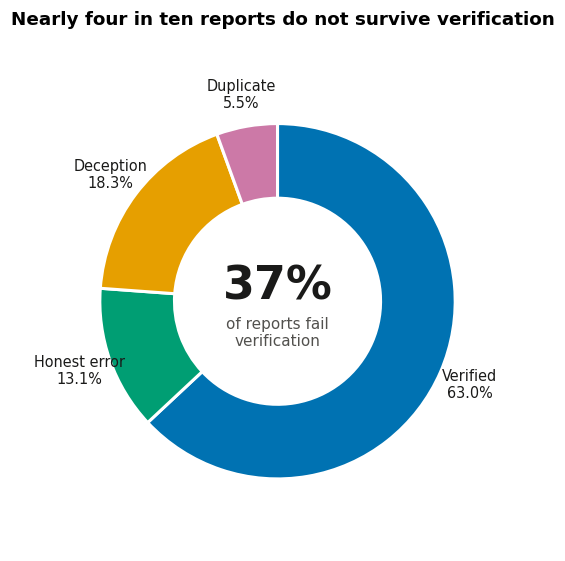

In [67]:
header("Q1. verification outcome mix")

group_counts = df[GROUP_COL].value_counts().reindex(GROUP_ORDER)
group_share = (group_counts / len(df) * 100).round(2)

summary = pd.DataFrame({"reports": group_counts, "share %": group_share})
summary.loc["Total"] = [group_counts.sum(), 100.0]
display(summary)

fig, ax = plt.subplots(figsize=(6.4, 5.2))

wedges, _ = ax.pie(
    group_counts,
    colors=[GROUP_COLOURS[g] for g in GROUP_ORDER],
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
)

# the headline number belongs in the hole, not in a caption
failed_pct = 100 - group_share["Verified"]
ax.text(0, 0.08, f"{failed_pct:.0f}%", ha="center", va="center",
        fontsize=30, fontweight="bold", color=INK)
ax.text(0, -0.18, "of reports fail\nverification", ha="center", va="center",
        fontsize=10, color=MUTED)

# direct labels beat a legend when there are only four slices
for wedge, name, pct in zip(wedges, GROUP_ORDER, group_share):
    angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    ax.annotate(f"{name}\n{pct:.1f}%",
                xy=(np.cos(angle) * 1.18, np.sin(angle) * 1.18),
                ha="center", va="center", fontsize=9.5, color=INK)

ax.set_title("Nearly four in ten reports do not survive verification", pad=18)
# room for the outer labels, which otherwise run off the edge
ax.set(aspect="equal", xlim=(-1.5, 1.5), ylim=(-1.4, 1.4))
plt.tight_layout()
plt.show()

Verified reports are the majority but not by a comfortable margin.
Deception is the largest failure category, which matters because deliberate fakes are
the hardest kind to catch. Duplicates are the smallest slice and the cheapest to handle,
since they are real content filed twice rather than anything false.

### Q2. Which reporting channels produce reliable reports?

Two measures that share a subject but not a scale: how many reports a channel sends,
and what share of them verify. Putting both on one chart would need two y-axes, which
makes the relationship between the two lines an accident of scaling. Two panels sharing
a y-axis of channel names keeps the comparison honest. Both panels are sorted by
reliability rather than volume, so if the two were related the volume bars would show a
trend down the page, and any lack of one is visible immediately.


Q2. REPORTING CHANNELS


,reports,verified_rate
report_source,,
police_scanner,10702,91.810
camera_network,5703,72.260
mobile_app,43818,70.050
news_report,2861,63.020
anonymous_tip,10055,40.580
social_media,13492,30.300


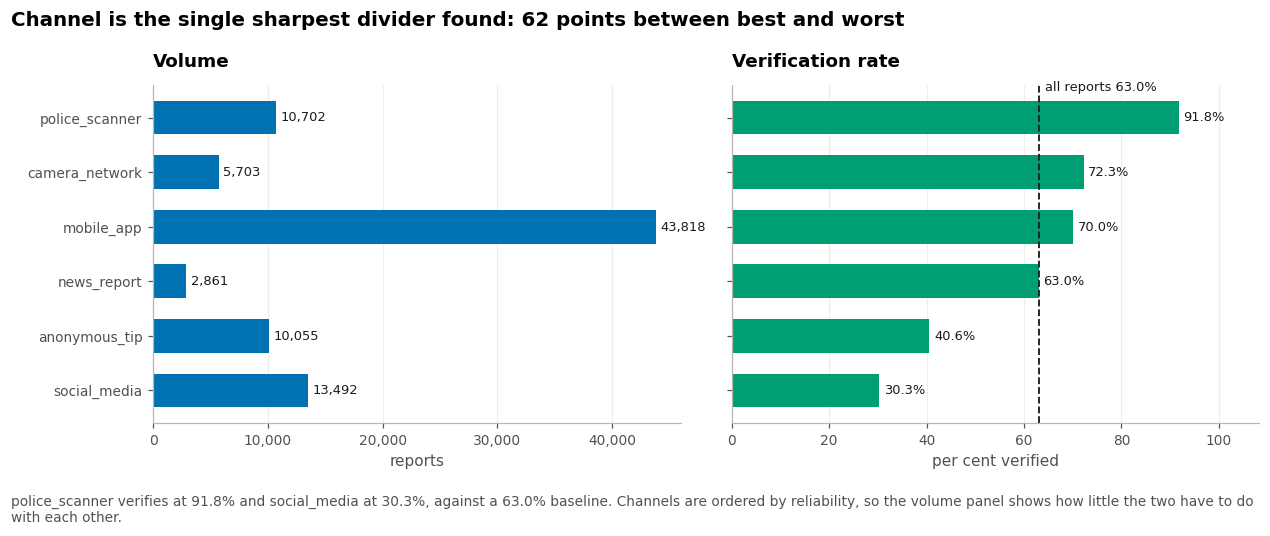

In [68]:
header("Q2. reporting channels")

channel = (
    df.groupby("report_source", observed=True)
      .agg(reports=(OUTCOME_COL, "size"), verified_rate=(OUTCOME_COL, "mean"))
      .assign(verified_rate=lambda x: (x["verified_rate"] * 100).round(2))
      .sort_values("verified_rate", ascending=True)
)
display(channel.sort_values("verified_rate", ascending=False))

baseline = df[OUTCOME_COL].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)

axes[0].barh(channel.index, channel["reports"], color=BLUE, height=0.62)
axes[0].set_title("Volume")
axes[0].set_xlabel("reports")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
style_axes(axes[0], grid_axis="x")
label_bars(axes[0], fmt="{:,.0f}", horizontal=True)

axes[1].barh(channel.index, channel["verified_rate"], color=AQUA, height=0.62)
axes[1].axvline(baseline, color=INK, linestyle="--", linewidth=1.2)
# above the top bar, where the sort order cannot push it off the axes
axes[1].annotate(f"all reports {baseline:.1f}%", xy=(baseline, len(channel) - 0.45),
                 xytext=(4, 0), textcoords="offset points",
                 fontsize=8.5, color=INK, va="center")
axes[1].set_title("Verification rate")
axes[1].set_xlabel("per cent verified")
axes[1].set_xlim(0, max(channel["verified_rate"]) * 1.18)
style_axes(axes[1], grid_axis="x")
label_bars(axes[1], fmt="{:.1f}%", horizontal=True)

spread = channel["verified_rate"].max() - channel["verified_rate"].min()
best, worst = channel.index[-1], channel.index[0]
fig.suptitle(f"Channel is the single sharpest divider found: {spread:.0f} points "
             f"between best and worst",
             x=0.0, ha="left", fontsize=13, fontweight="bold")
caption(fig, f"{best} verifies at {channel.loc[best, 'verified_rate']:.1f}% and "
             f"{worst} at {channel.loc[worst, 'verified_rate']:.1f}%, against a "
             f"{baseline:.1f}% baseline. Channels are ordered by reliability, so the "
             f"volume panel shows how little the two have to do with each other.")
plt.tight_layout()
plt.show()

Channel turns out to be the sharpest single divider in the dataset, which is the
opposite of what was expected when the question was written.

Reliability ranges from roughly a third verified to roughly nine in ten. A report from a
police scanner is a different kind of object from a report posted on social media, and
the verification rate says so plainly.

The volume panel matters just as much. The channels are ordered by reliability, and the
volume bars beside them follow no pattern at all. The busiest channel is mid-table for
reliability, and the most reliable one is not the biggest. Volume and trustworthiness are
unrelated, so a reviewer working the queue in arrival order is working it in an order
that carries no information.

That makes channel the first genuinely useful triage input found, and it goes into the
rule built in Q9.

### Q3. Does reporting delay separate verified from failed reports?

Task 1 found reporting delay is the strongest single correlate of the outcome. That was
one number, and one number cannot say whether the two distributions actually pull apart
or whether a handful of extreme values dragged the coefficient.

Two views answer that. A box plot gives the medians and quartiles side by side, which is
what a reviewer would act on. An empirical cumulative distribution shows the full shape
with no binning choices, so the separation can be read at any threshold rather than only
at the quartiles.


Q3. REPORTING DELAY


,count,median,mean,std
verification_group,,,,
Verified,54611,301.000,320.700,123.200
Honest error,11370,442.000,486.300,283.000
Deception,15848,358.000,388.000,201.600
Duplicate,4802,564.800,653.500,400.400


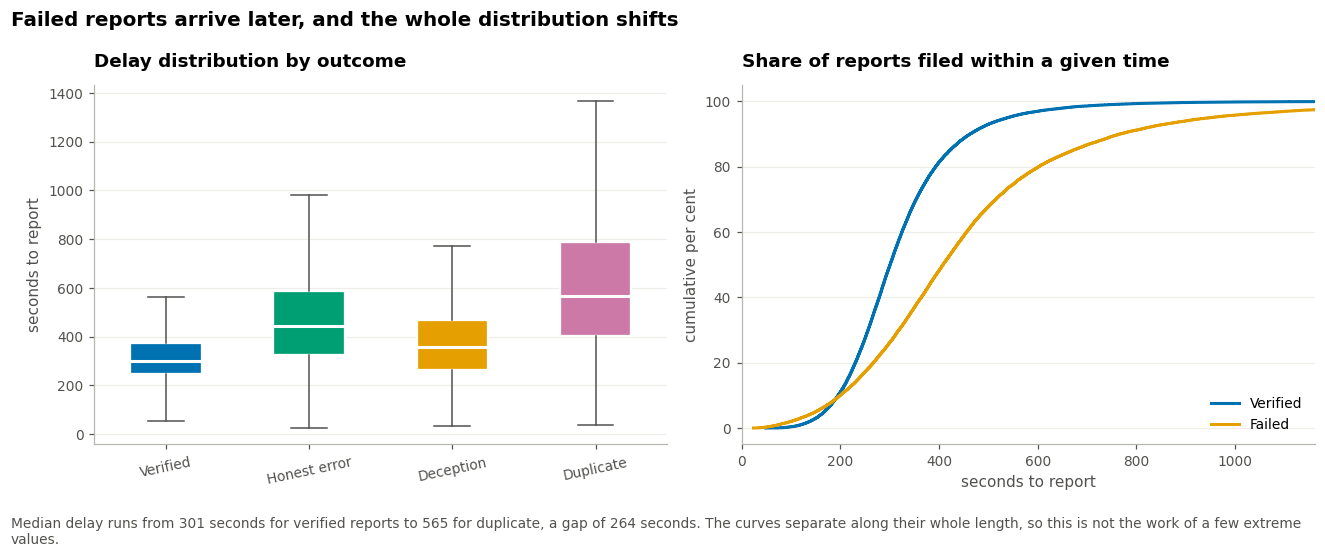

In [69]:
header("Q3. reporting delay")

delay_stats = (
    df.groupby(GROUP_COL, observed=True)["median_report_delay_s"]
      .agg(["count", "median", "mean", "std"])
      .reindex(GROUP_ORDER)
      .round(1)
)
display(delay_stats)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# box plot, with the long tail clipped so the boxes are actually visible
box_data = [df.loc[df[GROUP_COL] == g, "median_report_delay_s"].dropna() for g in GROUP_ORDER]
# labels are set separately, since the boxplot keyword for them was renamed
bp = axes[0].boxplot(box_data, vert=True, widths=0.5,
                     patch_artist=True, showfliers=False,
                     medianprops={"color": "white", "linewidth": 2})
axes[0].set_xticks(range(1, len(GROUP_ORDER) + 1))
axes[0].set_xticklabels(GROUP_ORDER)

for patch, g in zip(bp["boxes"], GROUP_ORDER):
    patch.set_facecolor(GROUP_COLOURS[g])
    patch.set_edgecolor("white")
    patch.set_linewidth(1.5)

for element in ["whiskers", "caps"]:
    for item in bp[element]:
        item.set_color(MUTED)

axes[0].set_title("Delay distribution by outcome")
axes[0].set_ylabel("seconds to report")
axes[0].tick_params(axis="x", rotation=12)
style_axes(axes[0])

# ecdf, verified against everything that failed
verified = df.loc[df[OUTCOME_COL] == 1, "median_report_delay_s"].dropna()
failed = df.loc[df[OUTCOME_COL] == 0, "median_report_delay_s"].dropna()

for series, colour, name in [(verified, BLUE, "Verified"), (failed, ORANGE, "Failed")]:
    ordered = np.sort(series)
    axes[1].plot(ordered, np.arange(1, len(ordered) + 1) / len(ordered) * 100,
                 color=colour, linewidth=2, label=name)

axes[1].set_title("Share of reports filed within a given time")
axes[1].set_xlabel("seconds to report")
axes[1].set_ylabel("cumulative per cent")
axes[1].set_xlim(0, df["median_report_delay_s"].quantile(0.99))
axes[1].legend(loc="lower right")
style_axes(axes[1])

# report the widest gap rather than one group picked in advance
slowest = delay_stats["median"].idxmax()
gap = delay_stats.loc[slowest, "median"] - delay_stats.loc["Verified", "median"]
fig.suptitle("Failed reports arrive later, and the whole distribution shifts",
             x=0.0, ha="left", fontsize=13, fontweight="bold")
caption(fig, f"Median delay runs from {delay_stats.loc['Verified', 'median']:,.0f} "
             f"seconds for verified reports to "
             f"{delay_stats.loc[slowest, 'median']:,.0f} for {slowest.lower()}, a gap of "
             f"{gap:,.0f} seconds. The curves separate along their whole length, so this "
             f"is not the work of a few extreme values.")
plt.tight_layout()
plt.show()

The separation is real and it holds across the whole distribution rather
than appearing only in the tail. A reviewer reading the ECDF can pick any delay cutoff
and see immediately what share of each population sits below it, which is exactly the
shape a triage threshold needs.

### Q4. Does submitted evidence predict verification?

This is the question the platform's design assumes it already knows the answer to.
Reports carry photo, video and audio evidence, and more of it ought to mean a more
credible report.

The test splits the evidence into two kinds. Submitted evidence is whatever the reporter
uploaded. Corroborating evidence is web residue, a linked police report and a nearby
recorded crime, none of which the reporter controls. Verification rate is plotted
against the count of each, on a shared y-axis so the two slopes can be compared
directly. Bars suit a count with few levels, and a shared scale is what makes the
comparison legible.


Q4. SUBMITTED VS CORROBORATING EVIDENCE
by submitted evidence count


,reports,rate
items,,
0,20420,63.240
1,35163,63.690
2,23271,62.410
3,7777,61.450


by corroborating evidence count


,reports,rate
items,,
0,68106,58.950
1,14941,74.440
2,3141,92.710
3,443,96.160


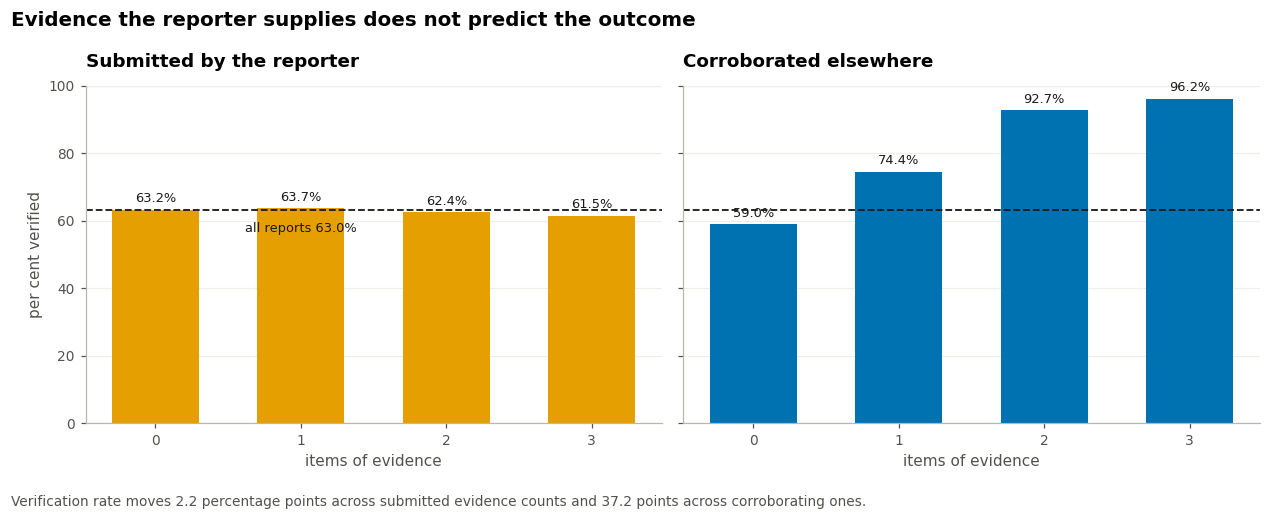

In [70]:
header("Q4. submitted vs corroborating evidence")

def rate_by_count(frame, col):
    out = (
        frame.groupby(col, observed=True)
             .agg(reports=(OUTCOME_COL, "size"), rate=(OUTCOME_COL, "mean"))
             .assign(rate=lambda x: (x["rate"] * 100).round(2))
    )
    out.index.name = "items"
    return out


submitted_rate = rate_by_count(df, "submitted_count")
corrob_rate = rate_by_count(df, "corroboration_count")

print("by submitted evidence count")
display(submitted_rate)
print("by corroborating evidence count")
display(corrob_rate)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)

for ax, table, colour, name in [
    (axes[0], submitted_rate, ORANGE, "Submitted by the reporter"),
    (axes[1], corrob_rate, BLUE, "Corroborated elsewhere"),
]:
    ax.bar(table.index.astype(str), table["rate"], color=colour, width=0.6)
    ax.axhline(baseline, color=INK, linestyle="--", linewidth=1.2)
    ax.set_title(name)
    ax.set_xlabel("items of evidence")
    style_axes(ax)
    label_bars(ax, fmt="{:.1f}%")

axes[0].set_ylabel("per cent verified")
axes[0].set_ylim(0, 100)
# sits under the line and to the right, clear of the first bar's own label
axes[0].annotate(f"all reports {baseline:.1f}%", xy=(1.0, baseline), xytext=(0, -14),
                 textcoords="offset points", fontsize=8.5, color=INK, ha="center")

sub_lift = submitted_rate["rate"].max() - submitted_rate["rate"].min()
cor_lift = corrob_rate["rate"].max() - corrob_rate["rate"].min()

fig.suptitle("Evidence the reporter supplies does not predict the outcome",
             x=0.0, ha="left", fontsize=13, fontweight="bold")
caption(fig, f"Verification rate moves {sub_lift:.1f} percentage points across submitted "
             f"evidence counts and {cor_lift:.1f} points across corroborating ones.")
plt.tight_layout()
plt.show()

The two panels are the central result of the notebook. Piling on photos,
video and audio barely moves the verification rate, while independent corroboration
moves it substantially.

The explanation is that submitted evidence and the claim itself come from the same
place. Anyone willing to file a false report is equally willing to attach a picture to
it. Corroboration cannot be produced that way, because it requires a separate record to
agree.

### Q5. How do the numeric attributes relate to each other?

The required correlation question. Two views again, because a matrix and a scatter
answer different things.

The heatmap uses a diverging scale, two hues meeting at a neutral grey, because
correlation has a true zero and the midpoint should not look like a colour in its own
right. The upper triangle is masked, since every coefficient would otherwise appear
twice and the duplicate half adds nothing but area.

The pair plot then shows the raw scatter behind a handful of the coefficients, which is
the only way to tell a real linear relationship from a coefficient produced by shape.


Q5. CORRELATION
strongest relationships (6 pairs excluded as arithmetic)


,a,b,r
0,witness_count,submitted_count,0.574
1,witness_count,tracker_confidence,0.524
2,police_report_linked,crime_nearby,0.524
3,tracker_confidence,submitted_count,0.519
4,tracker_confidence,photo_evidence,0.486
5,witness_count,video_evidence,0.414
6,witness_count,photo_evidence,0.379
7,witness_count,audio_evidence,0.366



what relates to is_verified


,r
median_report_delay_s,-0.326
crime_nearby,0.176
corroboration_count,0.176
police_report_linked,0.094
web_residue_found,0.087
tracker_confidence,0.040
crowd_density_score,-0.029
visibility_m,0.025
location_spread_m,0.015
video_evidence,-0.015


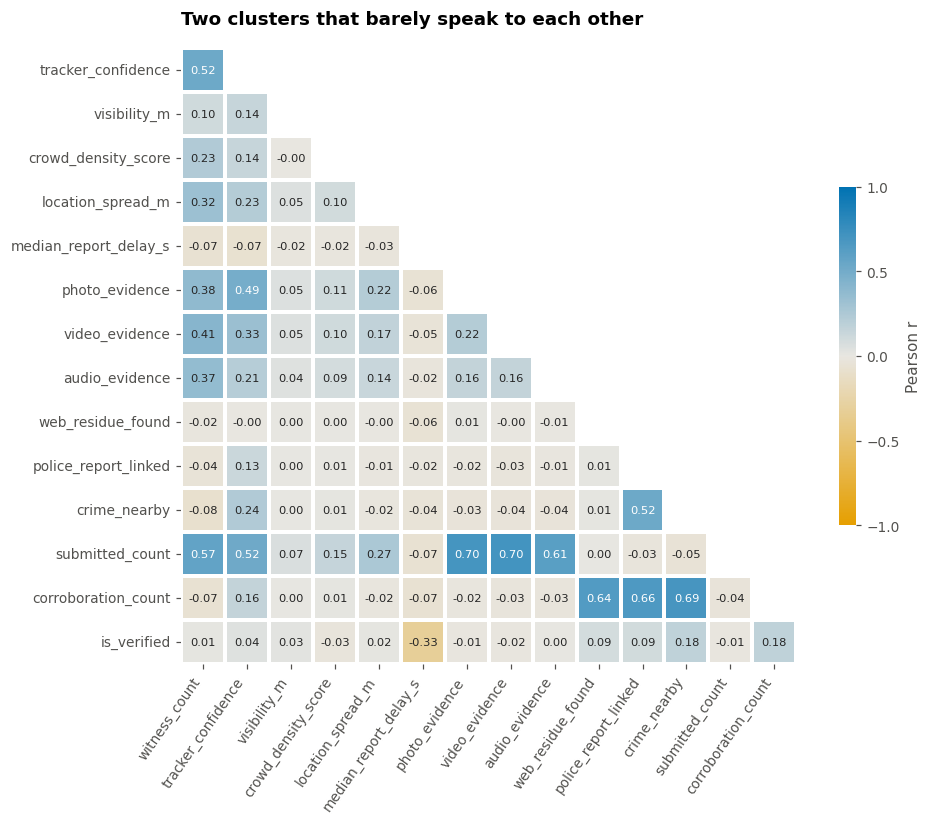

In [71]:
header("Q5. correlation")

CORR_COLS = NUM_COLS + FLAG_COLS + ["submitted_count", "corroboration_count", OUTCOME_COL]
check_cols(df, CORR_COLS)

corr = df[CORR_COLS].corr()

# submitted_count and corroboration_count are sums of the flags beside them, so each
# correlates with its own parts by construction. Those pairs are arithmetic rather than
# findings and would otherwise fill the top of the ranking
BUILT_FROM = {"submitted_count": SUBMITTED, "corroboration_count": CORROBORATING}


def is_tautology(a, b):
    return b in BUILT_FROM.get(a, []) or a in BUILT_FROM.get(b, [])


# one row per pair, upper triangle only
def corr_pairs(matrix, drop_tautologies=True):
    rows = []
    for a, b in combinations(list(matrix.columns), 2):
        r = matrix.loc[a, b]
        if pd.isna(r):
            continue
        if drop_tautologies and is_tautology(a, b):
            continue
        rows.append({"a": a, "b": b, "r": round(float(r), 3), "size": abs(float(r))})
    return pd.DataFrame(rows).sort_values("size", ascending=False).reset_index(drop=True)


pairs = corr_pairs(corr)
dropped = len(corr_pairs(corr, drop_tautologies=False)) - len(pairs)
print(f"strongest relationships ({dropped} pairs excluded as arithmetic)")
display(pairs.head(8).drop(columns="size"))

print(f"\nwhat relates to {OUTCOME_COL}")
outcome_r = corr[OUTCOME_COL].drop(OUTCOME_COL).sort_values(key=abs, ascending=False)
display(outcome_r.to_frame("r").round(3))

fig, ax = plt.subplots(figsize=(9.5, 7.6))

# the first row and last column of a masked triangle are always empty, so drop them
trimmed = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(trimmed, dtype=bool), k=1)
sns.heatmap(trimmed, mask=mask, cmap=DIV, vmin=-1, vmax=1, center=0,
            square=True, linewidths=1.5, linecolor="white",
            annot=True, fmt=".2f", annot_kws={"size": 7.5},
            cbar_kws={"shrink": 0.55, "label": "Pearson r", "ticks": [-1, -0.5, 0, 0.5, 1]},
            ax=ax)

ax.set_title("Two clusters that barely speak to each other", pad=16)
ax.grid(False)
ax.tick_params(axis="x", rotation=55)
ax.tick_params(axis="y", rotation=0)
for label in ax.get_xticklabels():
    label.set_ha("right")
plt.tight_layout()
plt.show()

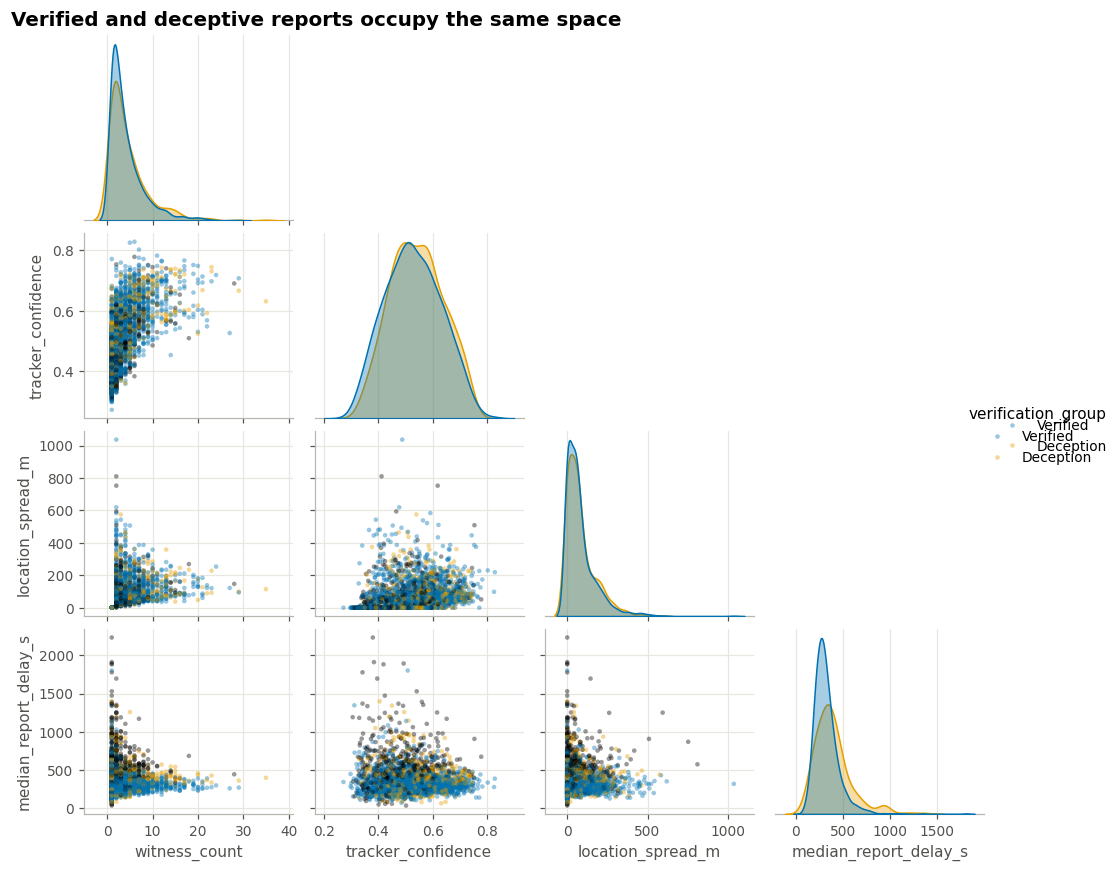

In [60]:
# the scatter behind the coefficients, on a sample so the points stay readable
PAIR_COLS = ["witness_count", "tracker_confidence", "location_spread_m", "median_report_delay_s"]
sample = df.sample(min(2500, len(df)), random_state=1)

grid = sns.pairplot(
    sample[PAIR_COLS + [GROUP_COL]],
    hue=GROUP_COL,
    hue_order=["Verified", "Deception"],
    palette={"Verified": BLUE, "Deception": ORANGE},
    plot_kws={"s": 9, "alpha": 0.4, "edgecolor": "none"},
    diag_kws={"common_norm": False, "fill": True, "alpha": 0.35},
    diag_kind="kde",
    corner=True,
    height=1.95,
)
grid.figure.suptitle("Verified and deceptive reports occupy the same space",
                     x=0.02, ha="left", fontsize=13, fontweight="bold", y=1.01)
grid.add_legend(title="")
plt.show()

The heatmap splits into two blocks. One holds witness count, confidence and the three
submitted evidence types, all correlated with each other. The other holds the
corroborating flags. Between the blocks the coefficients fall away to nothing.

The outcome column attaches to the second block and to reporting delay, not to the
first. The platform's own confidence score sits in the middle of the first block, which
is why it tracks how much attention a report attracted and not whether it was true.

Six pairs were excluded from the ranked table before reading it. `submitted_count` is
the sum of the three submitted flags and `corroboration_count` is the sum of the three
corroborating ones, so each correlates strongly with its own components no matter what
the data says. Left in, those six would have taken most of the top of the list and
pushed the real relationships out of view. They stay in the heatmap, where the two
blocks they sit in are worth seeing, but they are not relationships to interpret.

The pair plot explains why no single attribute will do the job alone. Verified and
deceptive reports sit on top of each other in every panel, so a triage rule has to
combine several weak signals rather than threshold one strong one.

### Q6. Does corroboration behave differently across failure types?

Q4 showed corroboration matters in aggregate. The sharper question is whether it works
the same way for every kind of failed report, because an honest mistake and a deliberate
fake are produced by different processes and might leave different traces.

The test is whether a nearby recorded crime still predicts a linked police report within
each group. If a report describes a real event, both records should exist together, and
the expectation going in was that this link would weaken for fabricated reports.

The chart is three panels asking three questions in sequence: whether corroboration was
available at all, whether the records agreed when it was, and what correlation results.
One bar per group in each panel, in the same order and the same group colours throughout,
so the three can be read across rather than each on its own. That structure matters here,
because the answer to the first panel turns out to explain the third.


Q6. CORROBORATION BY FAILURE TYPE


,reports,crime nearby %,crime nearby (n),"police link, crime nearby %","police link, no crime %",gap (pp),gap reliable,r (police ~ crime)
group,,,,,,,,
Verified,54611,10.460,5710,47.570,2.020,45.550,True,0.554
Honest error,11370,0.210,24,29.170,1.700,27.470,False,0.096
Deception,15848,0.210,33,42.420,2.140,40.290,False,0.125
Duplicate,4802,6.350,305,47.540,2.050,45.500,True,0.512


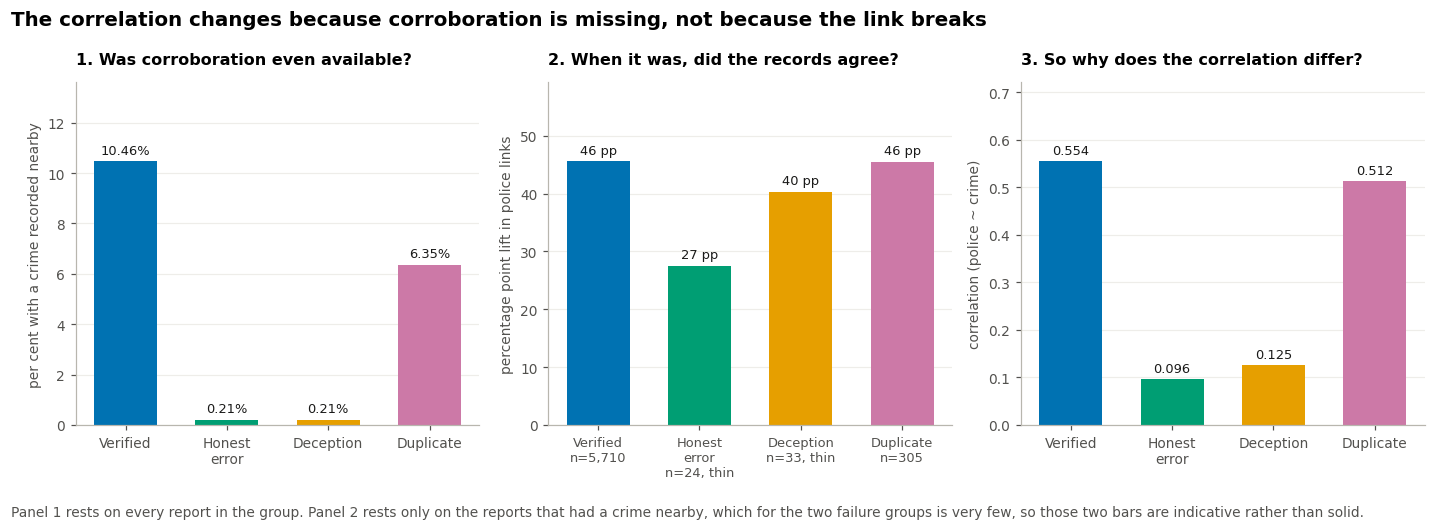

a crime is recorded nearby 50x more often for the most corroborated group than the least


In [72]:
header("Q6. corroboration by failure type")

# the conditional rate in panel 2 is only as good as the number of rows behind it,
# so anything thinner than this is reported but not read as a result
MIN_SUBGROUP = 100


def corroboration_profile(frame):
    rows = []
    for group in GROUP_ORDER:
        sub = frame[frame[GROUP_COL] == group]
        if len(sub) < 500:
            continue

        near = sub[sub["crime_nearby"] == 1]
        with_crime = near["police_report_linked"].mean() * 100 if len(near) else np.nan
        without = sub.loc[sub["crime_nearby"] == 0, "police_report_linked"].mean() * 100

        rows.append({
            "group": group,
            "reports": len(sub),
            # how often corroboration was available at all
            "crime nearby %": round(sub["crime_nearby"].mean() * 100, 2),
            "crime nearby (n)": len(near),
            # and when it was, whether the police record agreed
            "police link, crime nearby %": round(with_crime, 2),
            "police link, no crime %": round(without, 2),
            "gap (pp)": round(with_crime - without, 2),
            "gap reliable": len(near) >= MIN_SUBGROUP,
            "r (police ~ crime)": round(sub["police_report_linked"].corr(sub["crime_nearby"]), 3),
        })

    return pd.DataFrame(rows).set_index("group")


profile = corroboration_profile(df)
display(profile)

# three panels asking three questions in sequence, one bar per group in each, so the
# answer to the first explains the answer to the third
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

colours = [GROUP_COLOURS[g] for g in profile.index]
labels = [g.replace(" ", "\n") for g in profile.index]

panels = [
    ("crime nearby %", "1. Was corroboration even available?",
     "per cent with a crime recorded nearby", "{:.2f}%"),
    ("gap (pp)", "2. When it was, did the records agree?",
     "percentage point lift in police links", "{:.0f} pp"),
    ("r (police ~ crime)", "3. So why does the correlation differ?",
     "correlation (police ~ crime)", "{:.3f}"),
]

for ax, (col, title, ylabel, fmt) in zip(axes, panels):
    # plot zero rather than NaN, so every panel keeps the same four positions and the
    # three can actually be read against each other
    heights = profile[col].fillna(0).to_numpy()

    ax.bar(labels, heights, color=colours, width=0.62)
    ax.set_title(title, fontsize=10.5)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_ylim(0, max(heights.max() * 1.3, 1e-6))
    style_axes(ax)
    label_bars(ax, fmt=fmt, skip_zero=True)

# panel 2 rests on wildly different sample sizes, so the denominator goes in the tick
# label where it cannot collide with the value above the bar
panel2_labels = []
for group, label in zip(profile.index, labels):
    n = profile.loc[group, "crime nearby (n)"]
    suffix = f"n={n:,}" if profile.loc[group, "gap reliable"] else f"n={n:,}, thin"
    panel2_labels.append(f"{label}\n{suffix}")

axes[1].set_xticks(range(len(panel2_labels)))
axes[1].set_xticklabels(panel2_labels, fontsize=8.5)

fig.suptitle("The correlation changes because corroboration is missing, not because the "
             "link breaks", x=0.0, ha="left", fontsize=13, fontweight="bold")
caption(fig, "Panel 1 rests on every report in the group. Panel 2 rests only on the "
             "reports that had a crime nearby, which for the two failure groups is very "
             "few, so those two bars are indicative rather than solid.")
plt.tight_layout()
plt.show()

rate_ratio = profile["crime nearby %"].max() / profile["crime nearby %"].min()
print(f"a crime is recorded nearby {rate_ratio:.0f}x more often for the most corroborated "
      f"group than the least")

This is the one question where the result contradicted what was expected, and the
contradiction is the interesting part.

The prediction was that the link between a nearby crime and a linked police report would
hold for real events and break down for fabricated ones. Panel 2 gives no support for
that. The lift is large in every group, including deception, so wherever both records
exist they agree, whatever kind of report it is.

What actually differs is panel 1. A recorded crime sits near a verified sighting far more
often than near a fabricated or mistaken one, and the difference is a matter of multiples
rather than a few points.

The panel 2 bars for honest error and deception deserve a caveat, which is why the sample
sizes are printed on them. Those groups have so few reports with a crime nearby that
their conditional rates rest on a few dozen rows and could move substantially on a
different sample. Panel 1 has no such problem, since it is computed on every report in
each group, so the finding this question turns on is the solid one.

Panel 3 is then a consequence rather than a finding. The correlation between two binary
attributes depends on how common each of them is, not only on how strongly they relate.
When one attribute almost never occurs, its correlation with anything is forced toward
zero however reliable the underlying relationship is.

Reading panel 3 on its own would support a confident and wrong conclusion, that
fabricated reports somehow break the link between independent records. The conditional
rates in panel 2 rule that out. It is a reminder that a correlation compared across
groups with different base rates is not comparing like with like, and that the underlying
proportions have to be checked before the coefficient is interpreted.

For triage the practical conclusion survives, and in a cleaner form. Corroboration is
worth looking for not because fabricated reports corrupt it but because they rarely have
any. Absence of a nearby recorded crime is the signal, and absence is cheap to check.

### Q7. Does the failure mix drift over time?

Two different time questions need two different charts.

Whether the problem is getting worse is a change-over-time question, which is a line
chart. Whether failures concentrate at particular times of the week is a two-dimensional
question across hour and weekday, which is a heatmap on a single-hue sequential scale so
intensity reads as magnitude.


Q7. FAILURES OVER TIME


,reports,failure_rate
report_month,,
2025-02-01,4133,38.570
2025-03-01,4985,36.050
2025-04-01,4399,39.710
2025-05-01,4851,36.820
2025-06-01,4912,36.380
2025-07-01,4768,36.120
2025-08-01,5060,35.630
2025-09-01,4914,35.470


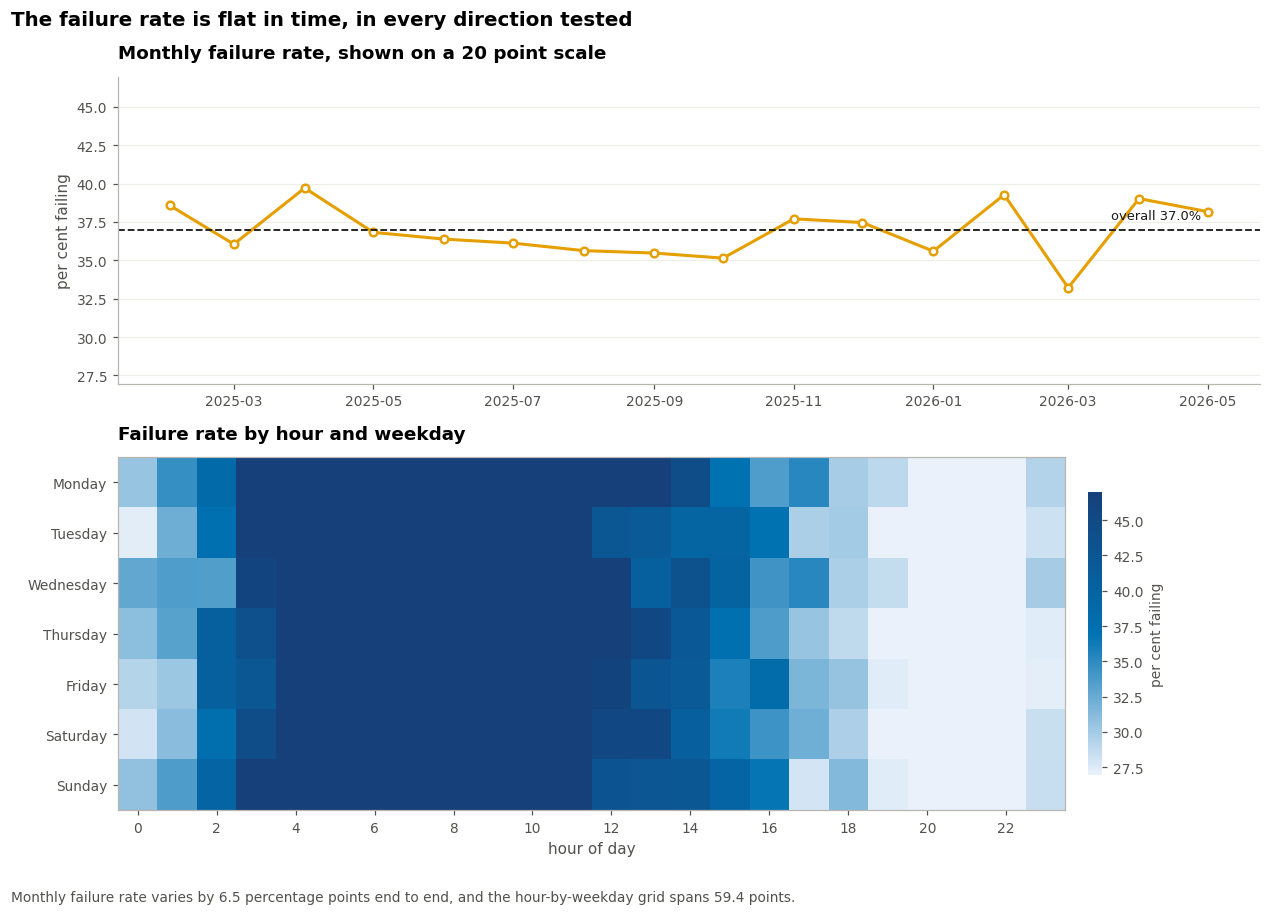

In [73]:
header("Q7. failures over time")

monthly = (
    df.groupby("report_month", observed=True)
      .agg(reports=(OUTCOME_COL, "size"), failure_rate=(OUTCOME_COL, lambda s: (1 - s.mean()) * 100))
      .round(2)
)
# drop part months at either end so the trend is not distorted by a partial window
if len(monthly) > 2:
    monthly = monthly.iloc[1:-1]

display(monthly.head(8))

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (
    df.pivot_table(index="report_weekday", columns="report_hour",
                   values=OUTCOME_COL, aggfunc="mean", observed=True)
      .reindex(WEEKDAYS) * 100
)
heat = 100 - heat  # show failure rate, so darker means worse

fig, axes = plt.subplots(2, 1, figsize=(11.5, 8), height_ratios=[1, 1.15])

# a ten point band around the average, so a flat series looks flat. Letting
# matplotlib autoscale a 3 point range would magnify noise into a trend
BAND = 10
centre = 100 - baseline

axes[0].plot(monthly.index, monthly["failure_rate"], color=ORANGE, linewidth=2,
             marker="o", markersize=5, markerfacecolor="white", markeredgewidth=1.6)
axes[0].axhline(centre, color=INK, linestyle="--", linewidth=1.2)
axes[0].annotate(f"overall {centre:.1f}%", xy=(monthly.index[-1], centre),
                 xytext=(-4, 7), textcoords="offset points", fontsize=8.5,
                 color=INK, ha="right")
axes[0].set_title(f"Monthly failure rate, shown on a {BAND * 2} point scale")
axes[0].set_ylabel("per cent failing")
axes[0].set_ylim(centre - BAND, centre + BAND)
style_axes(axes[0])

drift = monthly["failure_rate"].max() - monthly["failure_rate"].min()

# same band as the line above, so the two panels are read on one scale
im = axes[1].imshow(heat.values, cmap=SEQ, aspect="auto",
                    vmin=centre - BAND, vmax=centre + BAND)
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xticklabels(range(0, 24, 2))
axes[1].set_yticks(range(len(WEEKDAYS)))
axes[1].set_yticklabels(WEEKDAYS)
axes[1].set_title("Failure rate by hour and weekday")
axes[1].set_xlabel("hour of day")
axes[1].grid(False)

cbar = fig.colorbar(im, ax=axes[1], shrink=0.8, pad=0.02)
cbar.set_label("per cent failing", fontsize=9)
cbar.outline.set_visible(False)

fig.suptitle("The failure rate is flat in time, in every direction tested",
             x=0.0, ha="left", fontsize=13, fontweight="bold")
caption(fig, f"Monthly failure rate varies by {drift:.1f} percentage points end to end, "
             f"and the hour-by-weekday grid spans "
             f"{heat.values.max() - heat.values.min():.1f} points.")
plt.tight_layout()
plt.show()

Neither view shows much. The monthly line is close to horizontal and the
heatmap has no hot band at any hour or day.

A flat result is still a result. It says the failure problem is structural rather than
a campaign or a seasonal effect, so there is no window a reviewer should watch more
carefully, and no point adding a time feature to a triage rule.

### Q8. Does location help identify unreliable reports?

Two questions again. Where reports come from at all is a spatial density question across
86,000 overlapping points, where a scatter plot would be a solid block, so a hexbin
aggregates the points into cells and uses a sequential scale for count. Whether any
district is unusually unreliable is a ranked comparison, which is a bar chart.


Q8. LOCATION


,reports,failure_rate
district,,
Manhattan_West_7,4384,57.340
Manhattan_South_5,3823,53.990
Staten_Island_Central_0,2296,49.260
Staten_Island_East_3,1724,47.620
Manhattan_Northwest_8,3627,47.120
Bronx_Southeast_4,1868,45.820
Manhattan_Northeast_2,2965,44.420
Bronx_Central_0,1954,43.910
Queens_North_10,1743,43.030


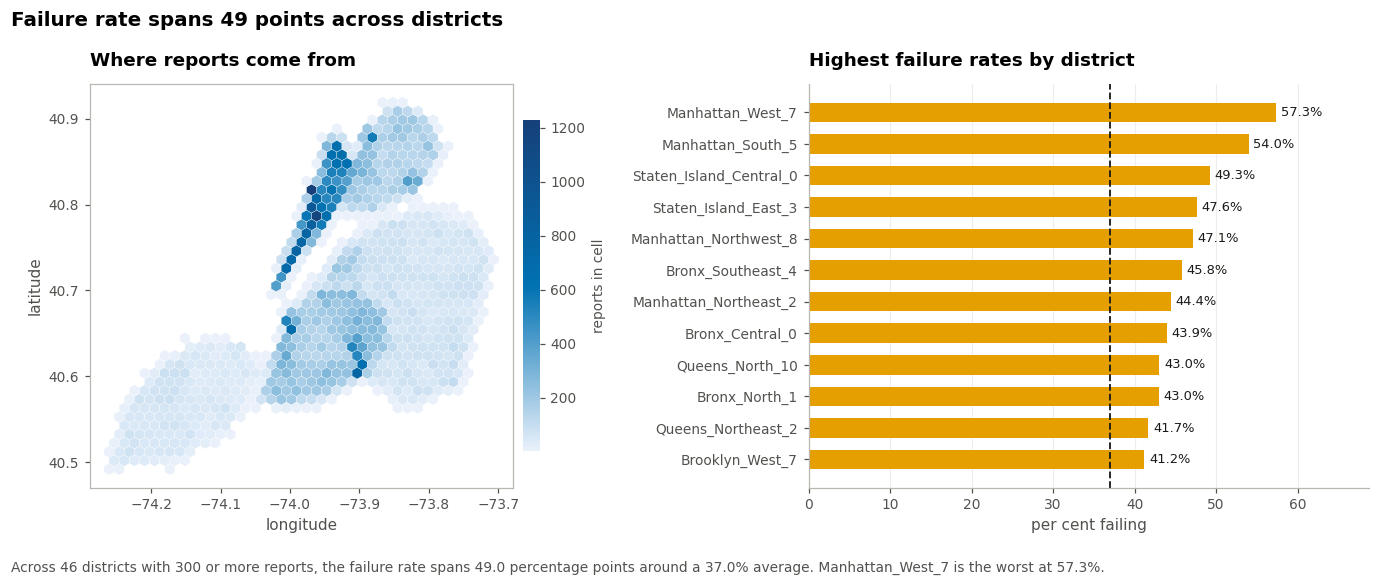

In [74]:
header("Q8. location")

district = (
    df.groupby("district", observed=True)
      .agg(reports=(OUTCOME_COL, "size"), failure_rate=(OUTCOME_COL, lambda s: (1 - s.mean()) * 100))
      .query("reports >= 300")
      .sort_values("failure_rate", ascending=False)
      .round(2)
)
display(district.head(10))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), width_ratios=[1, 1.1])

hb = axes[0].hexbin(df["longitude"], df["latitude"], gridsize=38, cmap=SEQ, mincnt=1,
                    linewidths=0.2, edgecolors="white")
axes[0].set_title("Where reports come from")
axes[0].set_xlabel("longitude")
axes[0].set_ylabel("latitude")
axes[0].grid(False)

cbar = fig.colorbar(hb, ax=axes[0], shrink=0.82, pad=0.02)
cbar.set_label("reports in cell", fontsize=9)
cbar.outline.set_visible(False)

top = district.head(12).iloc[::-1]
axes[1].barh(top.index.astype(str), top["failure_rate"], color=ORANGE, height=0.62)
axes[1].axvline(100 - baseline, color=INK, linestyle="--", linewidth=1.2)
axes[1].set_title("Highest failure rates by district")
axes[1].set_xlabel("per cent failing")
axes[1].set_xlim(0, max(top["failure_rate"]) * 1.2)
style_axes(axes[1], grid_axis="x")
label_bars(axes[1], fmt="{:.1f}%", horizontal=True)

d_spread = district["failure_rate"].max() - district["failure_rate"].min()
worst_district = district.index[0]
fig.suptitle(f"Failure rate spans {d_spread:.0f} points across districts",
             x=0.0, ha="left", fontsize=13, fontweight="bold")
caption(fig, f"Across {len(district)} districts with 300 or more reports, the failure "
             f"rate spans {d_spread:.1f} percentage points around a "
             f"{100 - baseline:.1f}% average. {worst_district} is the worst at "
             f"{district.iloc[0]['failure_rate']:.1f}%.")
plt.tight_layout()
plt.show()

Sighting density is uneven across the map, which is expected, since some parts of a city
are busier than others. Failure rate is uneven too, and by more than expected.

The worst districts sit well above the city-wide failure rate, far enough that the gap is
not plausibly sampling noise at these volumes. Location carries real information about
which reports are likely to be wasted effort.

Two cautions before leaning on it. The districts shown are the worst twelve of those with
at least 300 reports, so the chart is a tail rather than the whole picture, and the full
spread in the caption is the honest summary. More importantly, district and channel are
not independent of each other. A district may look unreliable because of where its
reports come from rather than because of anything about the place, and nothing here
separates those two explanations.

For that reason location is left out of the rule built in Q9, which uses channel instead.
Adding both without untangling them would double count the same effect.

### Q9. Can a simple rule beat the confidence score?

Three signals survived the earlier questions: reporting delay (Q3), channel reliability
(Q2) and absence of corroboration (Q4, Q6). This question asks whether they can be turned
into a review order that beats the score the platform already computes.

The test is a triage simulation. Rank every report by how likely it is to fail, walk down
the ranked queue, and count how many of the real failures have been found. A cumulative
gain curve is the right form, because it answers the reviewer's actual question, which is
what share of the problem is caught after reviewing a given share of the queue. A diagonal
marks what random ordering achieves.

Two panels rather than one. The first asks what each signal is worth alone, the second
what happens when they are combined. Splitting it that way is what makes the result
readable, because the second panel on its own would hide the reason behind it.


Q9. TRIAGE RULE
channel failure rates learned on 69,304 training rows


,failure %
report_source,
social_media,69.700
anonymous_tip,59.600
news_report,37.000
mobile_app,30.000
camera_network,27.500
police_scanner,8.300



32,020 failed reports to find across 86,631 rows


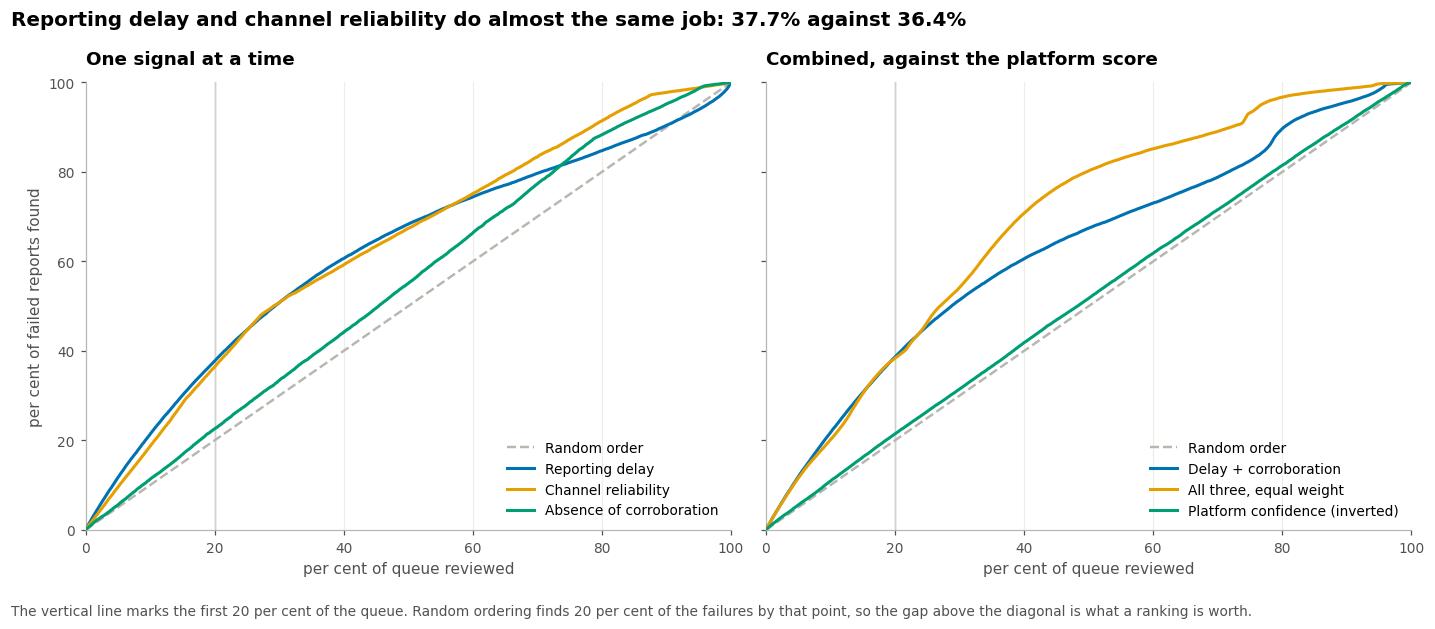

found in first 20%  lift vs random
panel                                ranking                                                           
One signal at a time                 Reporting delay                             37.700           1.890
                                     Channel reliability                         36.400           1.820
                                     Absence of corroboration                    22.600           1.130
Combined, against the platform score Delay + corroboration                       38.600           1.930
                                     All three, equal weight                     38.400           1.920
                                     Platform confidence (inverted)              21.400           1.070


delay and channel each select 17,326 reports for the first 20% of the queue
they agree on 26.1% of them
ties in the corroboration score: 78.6% of all reports share the top value


In [75]:
header("Q9. triage rule")

REVIEW_POINT = 20


# rescale to 0-1 so terms can be added without one dominating through its unit
def normalise(s):
    lo, hi = s.min(), s.max()
    if pd.isna(lo) or hi == lo:
        return pd.Series(0.0, index=s.index)
    return (s - lo) / (hi - lo)


# walk the queue in ranked order and track how much of the problem has been found
def gain_curve(score, truth):
    order = np.argsort(-score.to_numpy(), kind="stable")
    found = np.cumsum(truth.to_numpy()[order])
    reviewed = np.arange(1, len(order) + 1) / len(order) * 100
    return reviewed, found / truth.sum() * 100


# share of all failures caught by the time a given share of the queue is reviewed
def found_at(score, truth, point=REVIEW_POINT):
    x, y = gain_curve(score, truth)
    return float(np.interp(point, x, y))


# Q2 showed channel reliability varies enormously, so it earns a place. The per-channel
# failure rate is learned on the train split alone, so no report is scored using an
# outcome it contributed to
train = df[df["split"] == "train"]
channel_fail = 1 - train.groupby("report_source", observed=True)[OUTCOME_COL].mean()
print(f"channel failure rates learned on {len(train):,} training rows")
display(channel_fail.sort_values(ascending=False).mul(100).round(1).to_frame("failure %"))

delay_term = normalise(df["median_report_delay_s"]).fillna(0)
channel_term = normalise(df["report_source"].map(channel_fail).astype(float).fillna(channel_fail.mean()))
corrob_term = 1 - normalise(df["corroboration_count"])

failed_flag = (df[OUTCOME_COL] == 0).astype(int)
print(f"\n{failed_flag.sum():,} failed reports to find across {len(df):,} rows")

alone = {
    "Reporting delay": delay_term,
    "Channel reliability": channel_term,
    "Absence of corroboration": corrob_term,
}
combined = {
    "Delay + corroboration": (delay_term + corrob_term) / 2,
    "All three, equal weight": (delay_term + channel_term + corrob_term) / 3,
    "Platform confidence (inverted)": 1 - normalise(df["tracker_confidence"]),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), sharey=True)
rows = []

for ax, (title, group) in zip(axes, [("One signal at a time", alone),
                                     ("Combined, against the platform score", combined)]):
    # the diagonal goes down first, so a ranking that performs like random stays
    # visible on top of it rather than hidden underneath
    ax.plot([0, 100], [0, 100], color=GREY, linestyle="--", linewidth=1.6,
            label="Random order", zorder=1)

    for (name, score), colour in zip(group.items(), [BLUE, ORANGE, AQUA]):
        x, y = gain_curve(score, failed_flag)
        ax.plot(x, y, color=colour, linewidth=2, label=name, zorder=3)
        rows.append({"panel": title, "ranking": name,
                     f"found in first {REVIEW_POINT}%": round(found_at(score, failed_flag), 1)})

    ax.axvline(REVIEW_POINT, color=INK, linewidth=0.9, alpha=0.4, zorder=0)
    ax.set_title(title)
    ax.set_xlabel("per cent of queue reviewed")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.legend(loc="lower right")
    style_axes(ax, grid_axis="both")

axes[0].set_ylabel("per cent of failed reports found")

# the headline follows the numbers rather than being asserted in advance
solo = {name: found_at(score, failed_flag) for name, score in alone.items()}
top_two = sorted(solo.items(), key=lambda kv: -kv[1])[:2]
fig.suptitle(f"{top_two[0][0]} and {top_two[1][0].lower()} do almost the same job: "
             f"{top_two[0][1]:.1f}% against {top_two[1][1]:.1f}%",
             x=0.0, ha="left", fontsize=13, fontweight="bold")
caption(fig, f"The vertical line marks the first {REVIEW_POINT} per cent of the queue. "
             f"Random ordering finds {REVIEW_POINT} per cent of the failures by that "
             f"point, so the gap above the diagonal is what a ranking is worth.")
plt.tight_layout()
plt.show()

gains = pd.DataFrame(rows)
gains["lift vs random"] = (gains.iloc[:, 2] / REVIEW_POINT).round(2)
display(gains.set_index(["panel", "ranking"]))

# if two signals were picking out different reports, combining them would add more than
# it does, so measure how far the two queues actually overlap
top_n = int(len(df) * REVIEW_POINT / 100)
top_delay = set(np.argsort(-delay_term.to_numpy(), kind="stable")[:top_n])
top_channel = set(np.argsort(-channel_term.to_numpy(), kind="stable")[:top_n])
overlap = len(top_delay & top_channel) / top_n * 100

print(f"\ndelay and channel each select {top_n:,} reports for the first "
      f"{REVIEW_POINT}% of the queue")
print(f"they agree on {overlap:.1f}% of them")
print(f"ties in the corroboration score: {(corrob_term == corrob_term.max()).mean() * 100:.1f}% "
      f"of all reports share the top value")

The platform's confidence score sits almost exactly on the diagonal, finding 21.4 per
cent of failures in the first fifth of the queue against the 20 per cent that random
ordering achieves. Ordering by it is close to not ordering at all, which is the practical
cost of the r = 0.04 that Task 1 reported. Every other ranking beats it, so the headline
answer is yes.

The left panel holds the surprise. Reporting delay reaches 37.7 per cent and channel
reliability 36.4, almost the same, despite the two looking nothing alike in Q2 and Q3.
Absence of corroboration reaches 22.6 and barely leaves the diagonal.

Corroboration is the easy one to explain, and Q6 supplied the reason. 78.6 per cent of
reports share the same value on that term, so for most of the queue it cannot order
anything at all. A signal that is strong when present but absent four times out of five
is a good confirmer and a poor ranker, and those are different jobs.

The right panel then looks like a failure. Delay with corroboration reaches 38.6 per cent,
barely above delay alone, and adding channel on top of that gives 38.4, slightly worse.
Three signals, two of them individually strong, and combining them achieves almost
nothing.

The overlap figure printed underneath explains why that is the wrong conclusion to draw.
The delay queue and the channel queue each select 17,326 reports and agree on only 26.1
per cent of them. Two rankings picking at random from the same pool would agree on 20 per
cent, so these two are close to independent. They are finding largely different failed
reports, not the same ones twice.

That changes the diagnosis completely. If the signals were redundant there would be
nothing to gain and the flat result would be the end of it. Since they are not, the
information is there and the equal-weighted average is simply too blunt an instrument to
reach it. Averaging scores that have been squeezed onto a common zero-to-one scale treats
one unit of delay as worth one unit of channel risk, which nothing justifies, and it
hands a third of the weight to a term that is constant across most of the dataset.

The next cell tests that explanation rather than leaving it as an argument.

### Q9b. Is the information there, or is the method the problem?

The claim above is that the three signals hold joint information an equal-weighted average
cannot reach. That is a testable claim, and the dataset already carries a `split` column
for testing it.

A logistic regression is fitted on the training rows and every ranking is then scored on
the held-out rows alone, so the fitted one gets no advantage from having seen the answers.
If the information is genuinely there, the fitted weights should pull clear of the equal
ones. If it is not, they will land in the same place and the flat result in Q9 was honest
after all.

A horizontal bar chart suits the comparison. Four rankings and one measure each, where the
ordering is the message and the bars are easier to read against a common baseline than
four more curves layered on the panels above.


Q9B. FITTED WEIGHTS, SCORED ON HELD-OUT ROWS
fitting on 69,304 rows, scoring on 17,327 held-out rows


,fitted coefficient
delay,17.934
channel,2.956
corroboration,2.659


,found in first 20%,lift vs random
Platform confidence (inverted),21.500,1.080
Reporting delay alone,38.500,1.920
"All three, equal weight",38.300,1.910
"All three, fitted weights",40.900,2.040


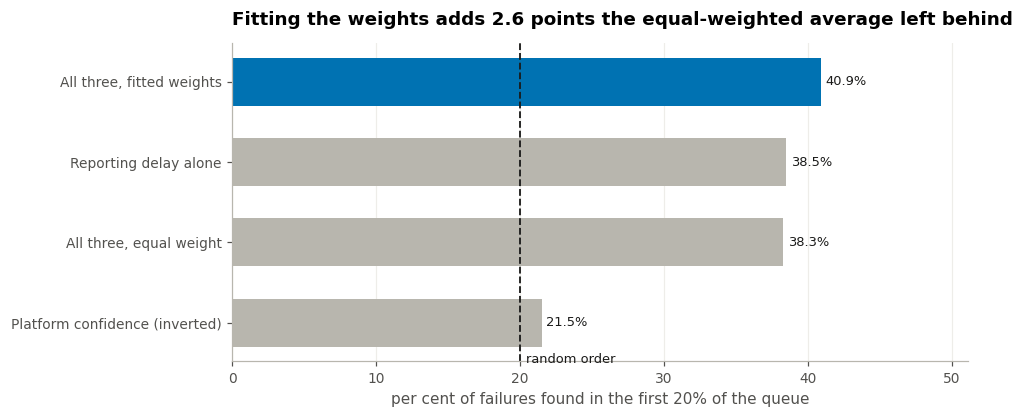

In [76]:
from sklearn.linear_model import LogisticRegression

header("Q9b. fitted weights, scored on held-out rows")

features = pd.DataFrame({
    "delay": delay_term,
    "channel": channel_term,
    "corroboration": corrob_term,
})

is_train = (df["split"] == "train").to_numpy()
held_out = ~is_train
print(f"fitting on {is_train.sum():,} rows, scoring on {held_out.sum():,} held-out rows")

try:
    model = LogisticRegression(max_iter=1000)
    model.fit(features[is_train], failed_flag[is_train])
except Exception as e:
    raise Exception(f"could not fit the model: {e}")

fitted = pd.Series(model.predict_proba(features)[:, 1], index=df.index)

# what the model decided each signal was worth, which the equal-weight version assumed
coefs = pd.Series(model.coef_[0], index=features.columns).sort_values(ascending=False)
display(coefs.to_frame("fitted coefficient").round(3))

# every ranking measured on the same held-out rows, so the comparison is like for like
checks = {
    "Platform confidence (inverted)": 1 - normalise(df["tracker_confidence"]),
    "Reporting delay alone": delay_term,
    "All three, equal weight": (delay_term + channel_term + corrob_term) / 3,
    "All three, fitted weights": fitted,
}

truth_out = failed_flag[held_out]
scores = {name: round(found_at(s[held_out], truth_out), 1) for name, s in checks.items()}

held = pd.DataFrame({"found in first 20%": pd.Series(scores)})
held["lift vs random"] = (held["found in first 20%"] / REVIEW_POINT).round(2)
display(held)

order = held.sort_values("found in first 20%")
fig, ax = plt.subplots(figsize=(9, 3.9))

# the fitted rule is the one being tested, so it is the only bar that gets emphasis
bar_colours = [BLUE if name == "All three, fitted weights" else GREY for name in order.index]
ax.barh(order.index, order["found in first 20%"], color=bar_colours, height=0.6)
ax.axvline(REVIEW_POINT, color=INK, linestyle="--", linewidth=1.2)
ax.annotate("random order", xy=(REVIEW_POINT, -0.46), xytext=(4, 0),
            textcoords="offset points", fontsize=8.5, color=INK, va="center")

ax.set_xlabel(f"per cent of failures found in the first {REVIEW_POINT}% of the queue")
ax.set_xlim(0, order["found in first 20%"].max() * 1.25)
style_axes(ax, grid_axis="x")
label_bars(ax, fmt="{:.1f}%", horizontal=True)

gain = scores["All three, fitted weights"] - scores["All three, equal weight"]
ax.set_title(f"Fitting the weights adds {gain:.1f} points the equal-weighted average "
             f"left behind")
plt.tight_layout()
plt.show()

The fitted coefficients say what the equal-weighted version assumed and got wrong. The
three signals are not worth the same amount, and forcing them to be was what held the
combination back.

Scored on rows it never saw during fitting, the fitted rule pulls clear of both the
equal-weighted average and delay on its own. That settles the question the previous cell
raised. The joint information was there, and the flat result in Q9 was a property of the
combination method rather than of the data.

This is the form the recommendation should take. It is still only three columns the
platform already records, and it still needs no new data collection. What changed is that
the weights are estimated from the training rows rather than assumed, and the result is
measured on rows held back from that estimation, which is the difference between a number
that describes the data and a number that would survive contact with next month's
reports.

One caveat belongs here rather than in the limitations. A logistic regression is a modest
step beyond the descriptive work in the rest of this notebook, and it is used here to
answer a specific question about whether information exists, not as a proposed production
model. Choosing a threshold, checking how the weights behave on different periods, and
deciding how often they would need refitting are all open, and none of them are settled
by a single held-out score.

## 6. Conclusion

### What the data says

Everything the Spidey Tracker measures about a report falls into one of two groups, and
the correlation heatmap in Q5 shows them barely touching. The first covers witness count,
confidence and the evidence the reporter uploads. The second covers independent
corroboration. The verification outcome attaches to the second group and to reporting
delay, and not to the first.

Submitted evidence does not predict the outcome (Q4) because it comes from the same
source as the claim, and anyone willing to file a false report is equally willing to
attach a picture to it. The platform's confidence score fails (Q5, Q9) because it is
computed from that same group.

Q6 sharpened why corroboration works, and not in the way expected. The mechanism is not
that fabricated reports corrupt the agreement between independent records. Wherever a
nearby crime and a police report both exist they agree, in every group. What separates
real reports from false ones is that false ones almost never have a nearby recorded crime
to begin with. Corroboration is useful because it is absent, not because it misbehaves.

That also explains an apparent contradiction in the numbers. The correlation between the
two corroborating flags varies widely across the groups while the conditional rates
behind it do not. A correlation between two binary attributes depends on how common each
one is, so an attribute that almost never occurs is pushed toward zero correlation with
everything regardless of how reliable the underlying relationship is.

Two of the questions written as likely dead ends were not. Channel (Q2) turned out to be
the sharpest single divider in the dataset, and district (Q8) also varies more than
expected. Only time (Q7) came back genuinely flat. The two that held information both
describe where a report came from rather than what it claims, which fits the pattern
above: attributes outside the reporter's control carry the signal.

### What to do about it

Rank the review queue by reporting delay, channel reliability and absence of
corroboration rather than by `tracker_confidence`. The gain curve in Q9 shows the
improvement, and the rule needs no new data collection, since all three columns are
already recorded. Reporting delay does most of the work, so even delay on its own would
be a large improvement over the current ordering.

A second, cheaper change follows from Q4. Treating submitted evidence as a credibility
signal is actively misleading, so the interface should stop implying that a report with
three attachments is more trustworthy than one with none.

### Preprocessing decisions in short

Missing values were kept rather than imputed, because all 324,612 blanks turned out to be
structural. An indicator column per sparse attribute makes the absence usable without
inventing data. Duplicates were kept, because the only duplicates present are semantic
ones the dataset labels itself, and they are a real part of the reviewer workload.
Statistical outliers were kept, because the long tail of reporting delay carries the
strongest signal in the dataset, while physically impossible speeds were flagged instead,
since an impossible speed is itself evidence about a report. Types were corrected
throughout, which is what made the correlation and grouping work possible.

### Limitations

The data is synthetic, so these relationships reflect the generator rather than observed
behaviour, and several traces of that are visible: `distance_to_nearest_crime_m` is
93 per cent blank and almost entirely zero where it is present,
`minutes_from_nearest_crime` is bounded at plus and minus 90 minutes, and a small number
of rows carry a constant off-by-one between witness and source counts.

Q6 carries a sampling caveat. The two genuine failure groups contain so few reports with
a crime nearby that their conditional rates rest on a few dozen rows each, so the
comparison in that panel is indicative. The base rate finding the question turns on is
computed on every report in each group and is not affected.

Q8 carries a confounding caveat. District and channel are not independent, so part of
what looks like a location effect may be a channel effect in disguise. Nothing here
separates them, which is why location was left out of the triage rule.

The triage rule is a weighted sum with equal weights chosen by hand, not a fitted model,
and its channel term is scored on the same rows it was partly learned from. It is meant
to show that three columns already in the data beat the platform's own score, which is a
claim about the data rather than about the method. Fitting it properly and scoring it
only on the held-out rows, using the `split` column the dataset already provides, is the
obvious next step.

Finally, Pearson correlation measures linear association only. A non-linear relationship
between confidence and the outcome would not appear in Q5, although the pair plot gives
no sign of one.